# Seasonal gut microbiome dynamics of wild baboons

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Eyal708/functional-pca/blob/main/examples/baboon_microbiome.ipynb)

This notebook is a guided example of the `fpca` library on real data: long-term gut microbiome samples from 100 wild baboons in Amboseli, Kenya, collected between 2000 and 2013. It covers the three estimators of the library:

| Section | Estimator | Question |
|---|---|---|
| 4–8 | `PACE` (univariate FPCA) | What are the main patterns of seasonal variation of one genus? |
| 9 | `TwoLevelPACE` (two-level FPCA) | How much of that variation is a persistent trait of the baboon, and how much changes from year to year? |
| 10–11 | `MFPCA` (multivariate FPCA) | Which patterns do several genera share, at each level? |

Each step has a short **method** note (what the FPCA step does) and a short **Using `fpca`** note (which function to call, its input and its output). The docstrings have the full details.

**Data.** Björk, J. R. et al. (2022). Synchrony and idiosyncrasy in the gut microbiome of wild baboons. *Nature Ecology & Evolution*. [doi:10.1038/s41559-022-01773-4](https://doi.org/10.1038/s41559-022-01773-4). The raw 16S rRNA reads are in ENA under [ERP119849](https://www.ebi.ac.uk/ena/browser/view/ERP119849).
- `data/baboons_data.csv`: genus-level relative abundances, one row per fecal sample.
- `data/baboons_metadata.csv`: per-sample metadata (baboon, date, sex, social group, season, hydrological year, ...).

## 0. Imports

### Setup

The next cell makes the notebook run anywhere. On **Google Colab** it installs `fpca` from GitHub and reads the data files directly from the repository. Locally, after `pip install -e ".[examples]"` in a clone of the repository, it does nothing except point to the `data/` folder next to this notebook.

In [ ]:
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "git+https://github.com/Eyal708/functional-pca.git"], check=True)

# The data files: the local data/ folder if present, otherwise the copy on GitHub.
DATA_DIR = "data" if os.path.isdir("data") else "https://raw.githubusercontent.com/Eyal708/functional-pca/main/examples/data"
print("Reading data from:", DATA_DIR)

In [36]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fpca import (MFPCA, PACE, TwoLevelPACE, curves_from_long, explained_variance_ratio,
                  orient_eigenfunctions, permanova_table)
from fpca.plotting import (plot_feature_eigenfunctions, plot_mfpca_eigenfunctions, plot_modes_of_variation,
                           plot_scores, plot_scores_by)

# Print warnings as 'Category: message', without the file path of the code that raised them.
warnings.formatwarning = lambda message, category, *args, **kwargs: f"{category.__name__}: {message}\n"

## 1. Load the data

We join abundances and metadata on the sample ID. The 200 metadata rows without an abundance profile are dropped by the join.

In [4]:
abund = pd.read_csv(f"{DATA_DIR}/baboons_data.csv")
meta = pd.read_csv(f"{DATA_DIR}/baboons_metadata.csv")

df = meta.merge(abund, on="sample", how="inner")
df["date"] = pd.to_datetime(df["collection_date"], dayfirst=True)
taxa = [c for c in abund.columns if c != "sample"]

print(f"{len(df)} samples, {df.baboon_id.nunique()} baboons, {len(taxa)} genera")
print(f"Dates: {df.date.min():%Y-%m-%d} to {df.date.max():%Y-%m-%d}")
print(pd.crosstab(df.date.dt.month, df.season).T.to_string())

7791 samples, 100 baboons, 61 genera
Dates: 2000-05-13 to 2013-09-19
date     1    2    3    4    5    6    7    8    9    10   11   12
season                                                            
dry       0    0    0    0    0  525  652  544  698  685    0    0
wet     837  642  577  487  486    0    0    0    0    0  793  865


The `season` column follows a fixed calendar: the **wet season runs from November to May** and the **dry season from June to October**. A hydrological year (`hydro_year`) starts on 1 November, so it holds one wet season followed by one dry season.

## 2. From samples to curves

**CLR transform.** Relative abundances are compositional: each sample sums to 1, so the genera cannot vary independently. The centred log-ratio (CLR) transform maps each sample to unconstrained log-ratio coordinates,

$$\mathrm{clr}(x)_j = \log x_j - \frac{1}{D}\sum_{k=1}^{D} \log x_k .$$

Zeros are replaced by half the smallest non-zero abundance. The CLR is computed over **all** 61 genera, and we keep the six most abundant.

**What is a curve?** FPCA treats each curve as one noisy, partially observed function. Here **one curve is one baboon in one hydrological year**. The time axis `t` is months since 1 November (0 to 12): the wet season is $0 \le t < 7$ and the dry season $7 \le t < 12$. Every curve then lives on the same 12-month domain, but each has only a few samples at its own irregular times. These are **sparse, irregular functional data**, the setting PACE is built for. Samples a baboon gave on the same day are averaged. A baboon-year's social group is the group it was sampled in most often that year.

In [5]:
X = df[taxa].to_numpy(dtype=float)
X = np.where(X > 0, X, 0.5 * X[X > 0].min()) # Add pseudocount to zeroes
X = X / X.sum(axis=1, keepdims=True)
logX = np.log(X)
clr = pd.DataFrame(logX - logX.mean(axis=1, keepdims=True), columns=taxa, index=df.index)

N_TAXA = 6
top_taxa = df[taxa].mean().sort_values(ascending=False).index[:N_TAXA].tolist()
print("Most abundant genera:")
for t in top_taxa:
    print(f"  {t:35s} mean rel. abundance {df[t].mean():.3f}")

cols = ["baboon_id", "sex", "social_group", "hydro_year", "date"]
clr_df = (pd.concat([df[cols], clr[top_taxa]], axis=1)
          .groupby(["baboon_id", "sex", "hydro_year", "date"], as_index=False)
          .agg({"social_group": "first", **{t: "mean" for t in top_taxa}}))

d = clr_df["date"].dt
clr_df["t"] = (d.month - 11) % 12 + (d.day - 1) / d.days_in_month   # months since 1 November
clr_df["year"] = d.year + (d.dayofyear - 1) / 365.25                 # decimal calendar year, for plots
clr_df["curve"] = clr_df["baboon_id"] + " / " + clr_df["hydro_year"].astype(str)

# One row per curve (baboon-year), with the labels used later.
curve_info = (clr_df.groupby("curve")
              .agg(baboon_id=("baboon_id", "first"), sex=("sex", "first"),
                   hydro_year=("hydro_year", "first"),
                   social_group=("social_group", lambda s: s.mode().iloc[0]),
                   n_samples=("t", "size")))
print(f"\n{len(curve_info)} curves (baboon-years) from {curve_info.baboon_id.nunique()} baboons")

Most abundant genera:
  g_Bifidobacterium                   mean rel. abundance 0.336
  g_Prevotella_9                      mean rel. abundance 0.121
  g_Rikenellaceae_RC9_gut_group       mean rel. abundance 0.079
  g_Candidatus_Methanogranum          mean rel. abundance 0.069
  g_Megasphaera                       mean rel. abundance 0.046
  g_Dialister                         mean rel. abundance 0.034

1052 curves (baboon-years) from 100 baboons


**Using `fpca`: the curve format.** Every estimator takes curves as a list of `(times, values)` pairs, one pair of 1-D arrays per curve. Curves may have different lengths and different times. `curves_from_long(frame, value_col, curve_col, time_col)` builds this list from a long table with one row per observation. It returns the sorted curve labels and the matching list of curves:

```python
ids, curves = curves_from_long(clr_df, value_col="g_Bifidobacterium", curve_col="curve", time_col="t")
ids[0], curves[0]      # 'Baboon_101 / 2001', (array([...times...]), array([...values...]))
```

## 3. Exploring the data

`shade_seasons` is a plotting helper specific to this dataset. It marks the wet and dry seasons on a Nov–Oct axis or on a calendar-year axis.

In [6]:
MONTHS = ["Nov", "Dec", "Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct"]
WET, DRY = "#9cc3e6", "#e8c872"
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
SHORT = {t: t.removeprefix("g_").replace("Candidatus_", "Ca. ").replace("_gut_group", "") for t in top_taxa}
TAXON_COLORS = dict(zip(top_taxa, colors))
XLABEL = "Month (hydrological year)"


def shade_seasons(ax, calendar=False, legend=False):
    # Wet season Nov-May (blue), dry season Jun-Oct (sand). calendar=False: months-since-November
    # axis (0-12) with month tick labels; calendar=True: decimal calendar years.
    lo, hi = ax.get_xlim()
    if calendar:
        for y in range(int(np.floor(lo)) - 1, int(np.ceil(hi)) + 1):
            ax.axvspan(y + 151 / 365.25, y + 304 / 365.25, color=DRY, alpha=0.3, lw=0, zorder=0)
            ax.axvspan(y + 304 / 365.25, y + 1 + 151 / 365.25, color=WET, alpha=0.25, lw=0, zorder=0)
    else:
        ax.axvspan(0, 7, color=WET, alpha=0.25, lw=0, zorder=0)
        ax.axvspan(7, 12, color=DRY, alpha=0.3, lw=0, zorder=0)
        ax.set_xticks(np.arange(12) + 0.5, MONTHS, fontsize=8)
        ax.set_xticks(np.arange(13), minor=True)
        ax.tick_params(axis="x", which="major", length=0)
        lo, hi = 0, 12
    ax.set_xlim(lo, hi)
    if legend:
        ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=WET, alpha=0.5, label="wet season"),
                           plt.Rectangle((0, 0), 1, 1, color=DRY, alpha=0.6, label="dry season")],
                  frameon=False, fontsize=8, loc="upper right", ncol=2)

### 3.1 Raw samples over calendar time

Every point is one fecal sample, and every plot shows a different genus of the 6 most abundant bacterial genera. 

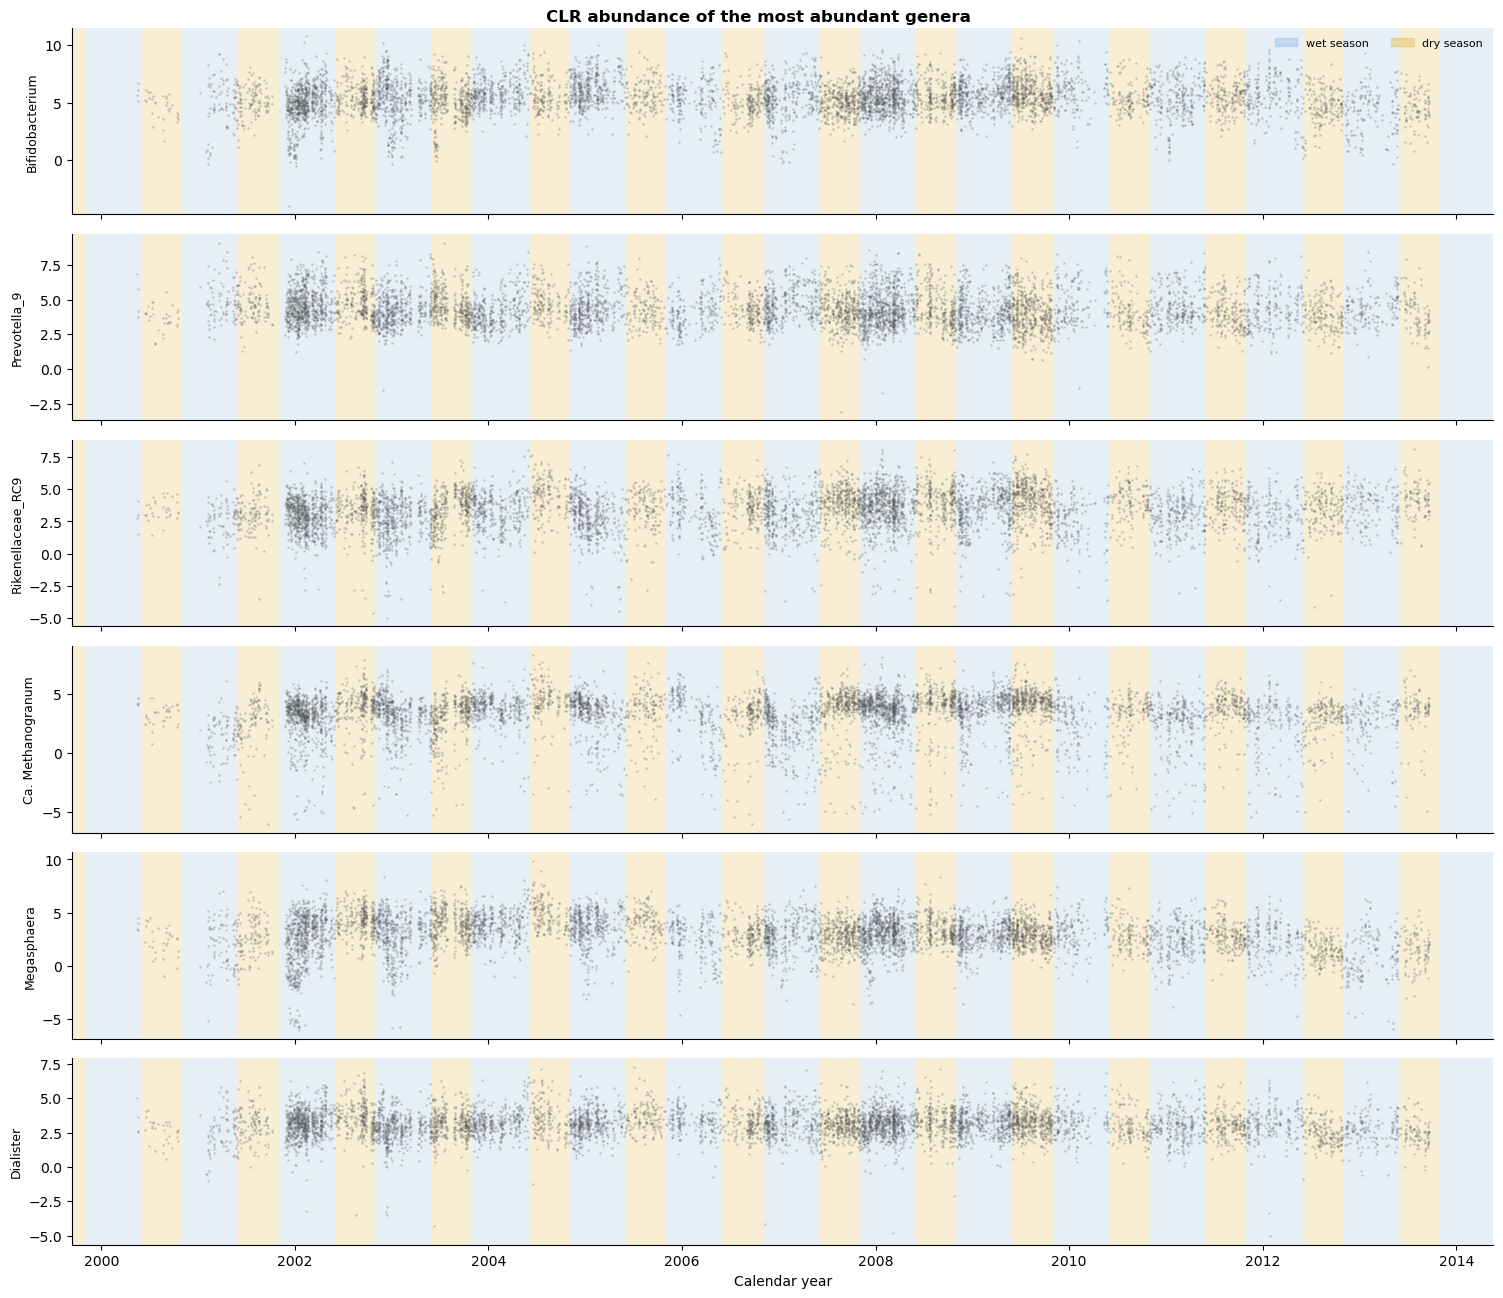

In [7]:
fig, axes = plt.subplots(N_TAXA, 1, figsize=(15, 2.2 * N_TAXA), sharex=True)
for r, (ax, taxon) in enumerate(zip(axes, top_taxa)):
    ax.scatter(clr_df["year"], clr_df[taxon], s=3, color="0.35", alpha=0.3, linewidths=0)
    ax.set_ylabel(SHORT[taxon], fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)
    shade_seasons(ax, calendar=True, legend=(r == 0))
axes[-1].set_xlabel("Calendar year")
fig.suptitle("CLR abundance of the most abundant genera", fontweight="bold")
fig.tight_layout()

### 3.2 Sampling design

How many samples each curve has, how many years each baboon contributes, and how the samples spread over the hydrological year. About 8% of the curves have a single sample. PACE uses them for the mean and the noise variance (a single point cannot inform the covariance surface), and scores them like every other curve.

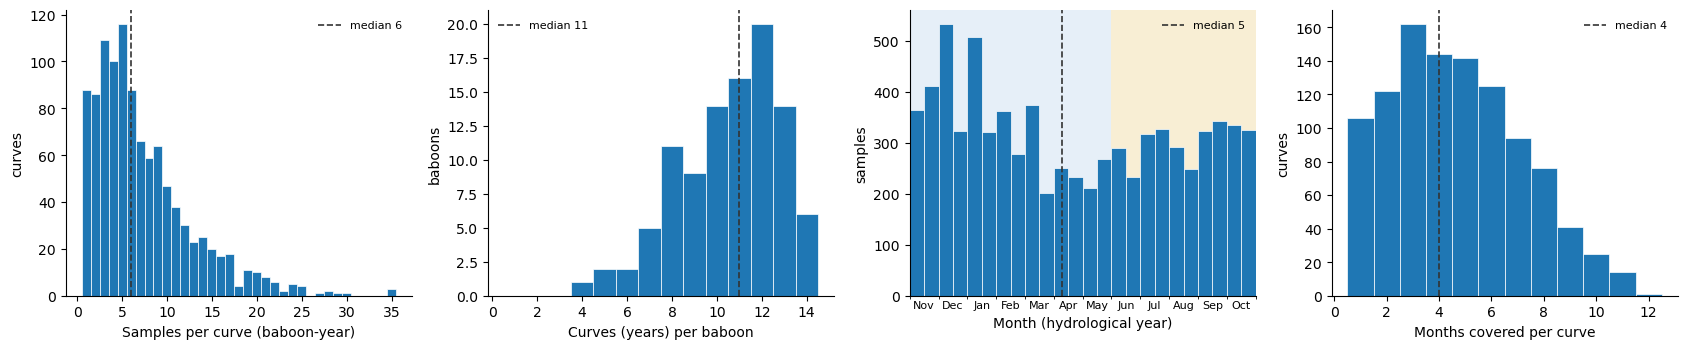

In [8]:
months_covered = clr_df.groupby("curve")["t"].agg(lambda t: np.unique(np.floor(t)).size)
panels = [
    (curve_info["n_samples"], np.arange(0.5, curve_info["n_samples"].max() + 1), "Samples per curve (baboon-year)", "curves"),
    (curve_info.groupby("baboon_id").size(), np.arange(0.5, 15), "Curves (years) per baboon", "baboons"),
    (clr_df["t"], np.arange(0, 12.01, 0.5), XLABEL, "samples"),
    (months_covered, np.arange(0.5, 13), "Months covered per curve", "curves"),
]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, (values, bins, xlabel, ylabel) in zip(axes, panels):
    ax.hist(values, bins=bins, color=colors[0], edgecolor="white", linewidth=0.5)
    ax.axvline(np.median(values), color="0.2", lw=1.2, ls="--", label=f"median {np.median(values):.0f}")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.legend(frameon=False, fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
shade_seasons(axes[2])
fig.tight_layout()

### 3.3 Curves

All baboon-year curves of each genus on the shared Nov–Oct axis (grey), with three densely sampled curves highlighted. This is the input FPCA works on.

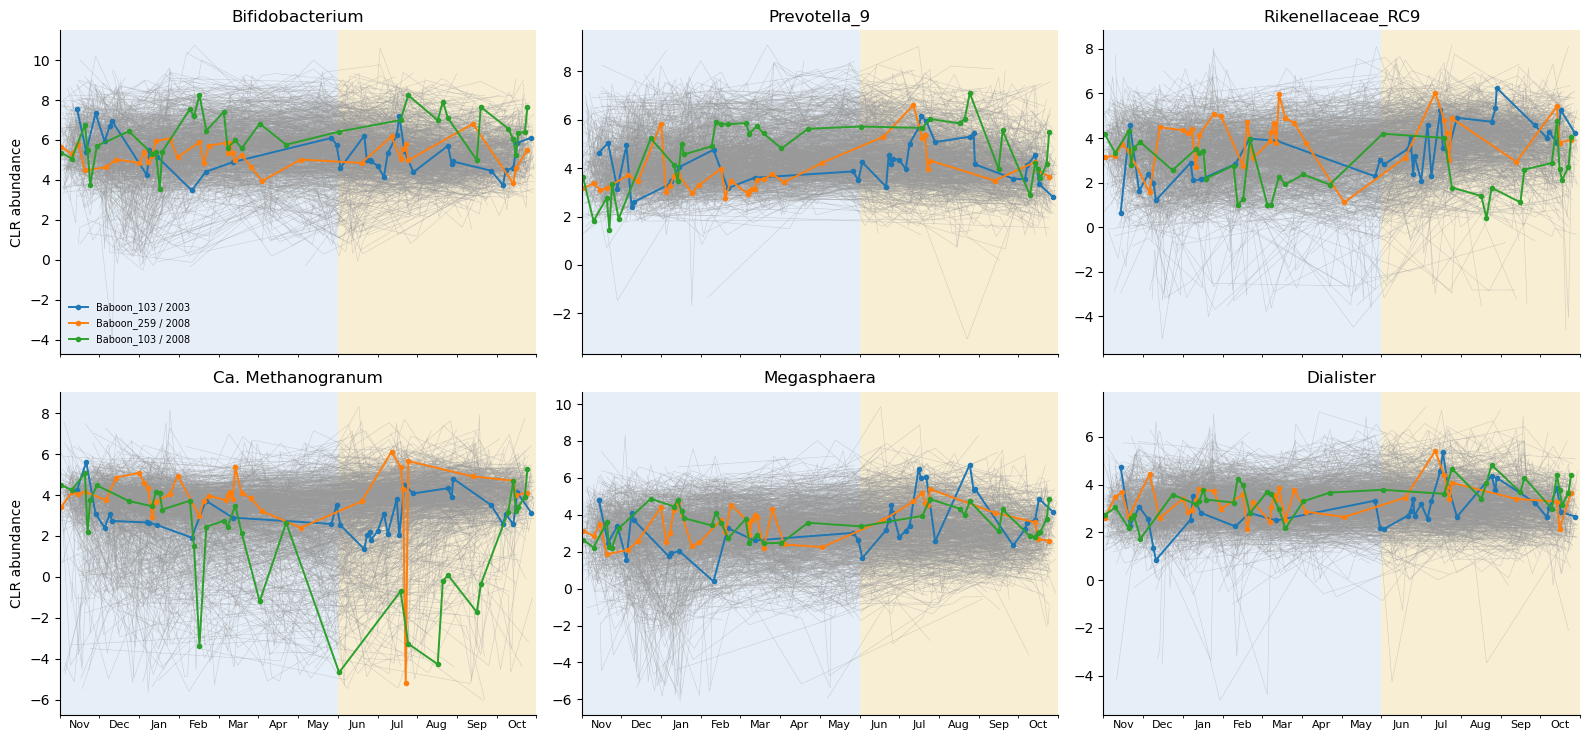

In [9]:
highlight = curve_info["n_samples"].sort_values(ascending=False).index[:3]

fig, axes = plt.subplots(2, 3, figsize=(16, 7.5), sharex=True)
for ax, taxon in zip(axes.flat, top_taxa):
    ids_t, curves_t = curves_from_long(clr_df, value_col=taxon, curve_col="curve", time_col="t")
    for t, y in curves_t:
        ax.plot(t, y, color="0.6", lw=0.4, alpha=0.4)
    for c, cid in zip(colors, highlight):
        t, y = curves_t[ids_t.index(cid)]
        ax.plot(t, y, "-o", color=c, lw=1.4, ms=3, label=cid)
    shade_seasons(ax)
    ax.set_title(SHORT[taxon])
    ax.spines[["top", "right"]].set_visible(False)
for ax in axes[:, 0]:
    ax.set_ylabel("CLR abundance")
axes[0, 0].legend(frameon=False, fontsize=7, loc="lower left")
fig.tight_layout()

## 4. Univariate FPCA with `PACE`

**Method.** PACE (Yao, Müller & Wang 2005) models every curve as $X_i(t) = \mu(t) + \sum_k \xi_{ik}\,\phi_k(t) + \varepsilon_{ij}$:
1. the **mean function** $\mu(t)$ is a smooth fit to all pooled samples: the average seasonal trajectory;
2. the **covariance surface** is smoothed from pairs of samples within each curve, and its **eigenfunctions** $\phi_k(t)$ are the main ways a curve departs from the mean. The eigenvalues give each component's share of variance;
3. the measurement-noise variance $\sigma^2$ is estimated from the diagonal of the covariance;
4. each curve's **scores** $\xi_{ik}$ are estimated by conditional expectation, which borrows strength from the whole sample, so even curves with one or two samples get scores.

**Using `fpca`.** `PACE(...).fit(curves)` estimates steps 1–3 from a list of `(times, values)` curves. The fitted model stores
- `grid_`: the evaluation grid;
- `mean_values_`: the mean function on that grid;
- `eigenfunction_values_`: the eigenfunctions, one row each;
- `eigenvalues_`: their eigenvalues;
- `noise_variance_`: the noise variance $\sigma^2$.

`explained_variance_ratio(model)` gives each component's share. The main settings are `method_smoothing="PS"` (P-splines), whose smoothness is set by `mean_penalty` and `covariance_penalty`, and `variance_threshold`, which decides how many components to keep. Curves with a single sample raise a warning and are kept.

**Signs.** Eigenfunctions are defined only up to sign. `orient_eigenfunctions(model)` flips each one so that its average over the year is positive, so a positive score means "above the mean". Call it right after `fit` and before computing any scores.

In [37]:
TAXON = top_taxa[0]
curve_ids, curves = curves_from_long(clr_df, value_col=TAXON, curve_col="curve", time_col="t")
info = curve_info.loc[curve_ids]              # curve labels, aligned with `curves`

PACE_SETTINGS = dict(method_smoothing="PS", mean_penalty=10.0, covariance_penalty=10.0,
                     ps_mean_n_segments=12, ps_n_segments=15, variance_threshold=1.0)
pace = PACE(**PACE_SETTINGS).fit(curves)
orient_eigenfunctions(pace)

fve = 100 * explained_variance_ratio(pace)
print(f"{TAXON}: {len(curves)} curves, {pace.n_components_available_} components retained")
print(f"Noise variance {pace.noise_variance_:.3f} (total variance {clr_df[TAXON].var():.3f})")
print("Variance explained (%):", np.round(fve, 1))

g_Bifidobacterium: 1052 curves, 13 components retained
Noise variance 1.258 (total variance 2.227)
Variance explained (%): [55.2 19.9  8.6  6.7  4.2  2.4  1.9  0.8  0.2  0.1  0.   0.   0. ]


## 5. Mean function and eigenfunctions

The mean, drawn over the raw samples, is the average seasonal trajectory. Each eigenfunction is a pattern by which a baboon-year deviates from it, and the panel title gives its share of variance. Read an eigenfunction together with its sign: a curve with a positive score lies above the mean where the eigenfunction is positive.

**Using `fpca`.** `PACE` has two plotting methods of its own: `plot_mean(ax=...)`, and `plot_eigenfunctions(n_components=...)`, which returns `(fig, axes)` so the panels can be restyled.

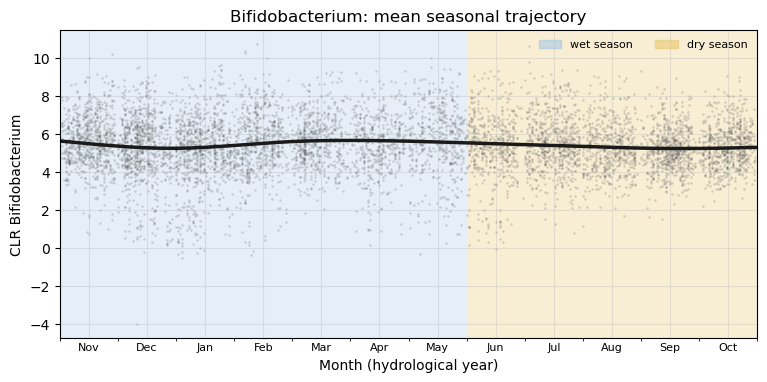

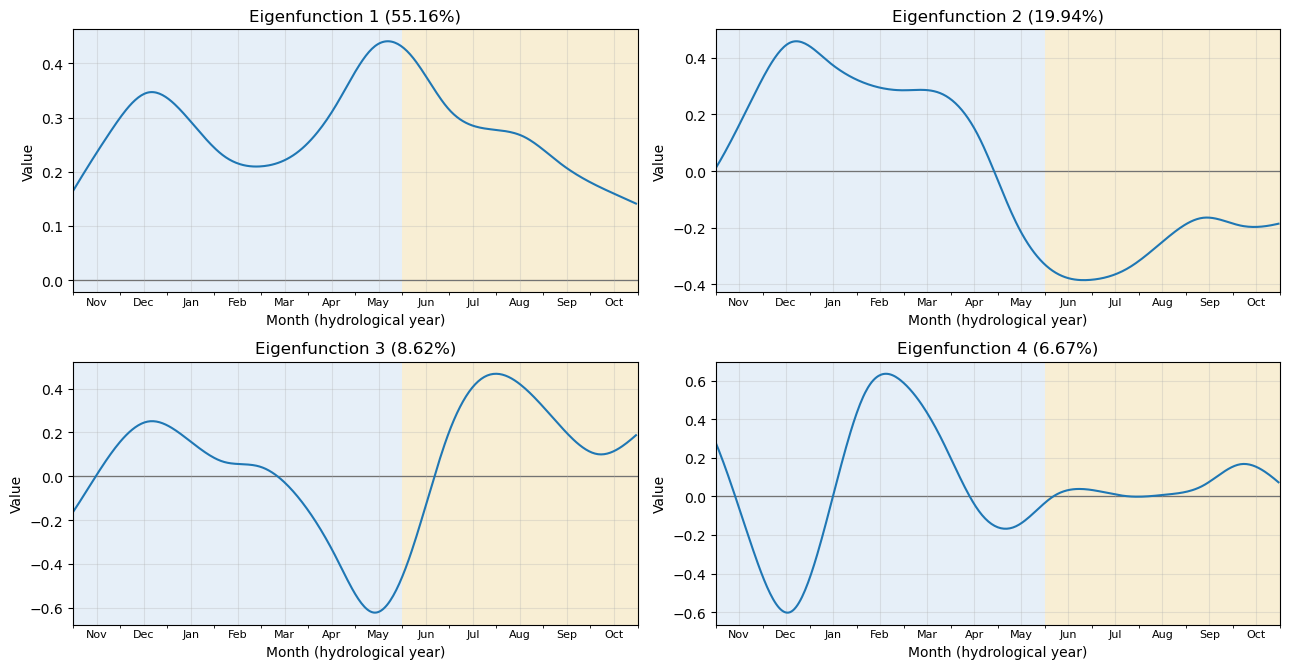

In [11]:
label = f"CLR {SHORT[TAXON]}"

fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(clr_df["t"], clr_df[TAXON], s=3, color="0.35", alpha=0.25, linewidths=0)
pace.plot_mean(ax=ax, color="0.1", lw=2.5)
shade_seasons(ax, legend=True)
ax.set_xlabel(XLABEL)
ax.set_ylabel(label)
ax.set_title(f"{SHORT[TAXON]}: mean seasonal trajectory")

n_show = min(4, pace.n_components_available_)
fig, axes = pace.plot_eigenfunctions(n_components=n_show, figsize=(13, 3.4 * int(np.ceil(n_show / 2))))
for ax in axes[:n_show]:
    shade_seasons(ax)
    ax.set_xlabel(XLABEL)
fig.tight_layout()

### 5.1 Reading the components: modes of variation

A **modes-of-variation** plot shows what the component does to an actual curve. Each panel draws the mean $\hat\mu(t)$ (grey) together with $\hat\mu(t) \pm 2\sqrt{\hat\lambda_k}\,\hat\phi_k(t)$: the trajectory of a baboon-year whose score on component $k$ is two standard deviations above (solid) or below (dashed) average, with every other score at zero.
- A component that moves the whole curve up or down describes a change in **level**.
- One whose ± curves cross the mean describes a change in **shape**: which part of the year is high and which is low.
- One whose ± curves look like the same bump moved earlier or later describes a change in **timing**.

**Using `fpca`.** `plot_modes_of_variation(model, n_components=4, scale=2.0, n_cols=2)` takes a fitted model and returns `(fig, axes)`, one panel per component. `scale` sets how many standard deviations $\sqrt{\hat\lambda_k}$ are added and subtracted.

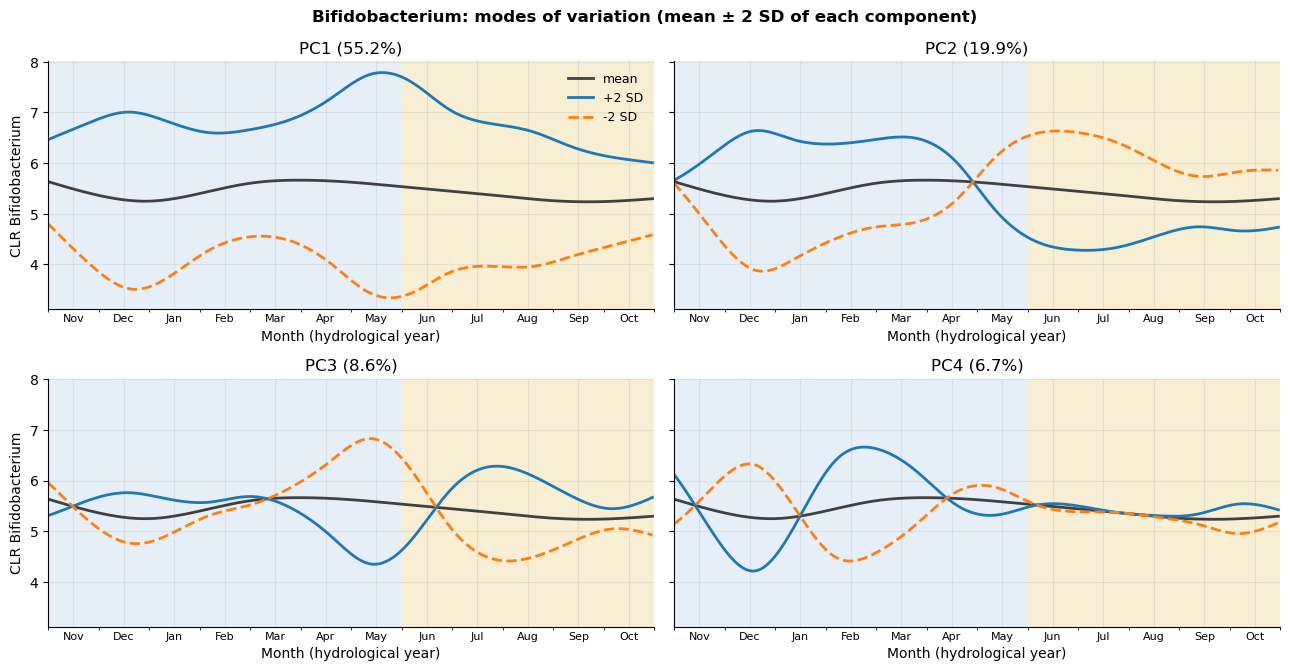

In [12]:
fig, axes = plot_modes_of_variation(pace, n_components=n_show, scale=2.0, n_cols=2,
                                    xlabel=XLABEL, ylabel=label, figsize=(13, 3.4 * int(np.ceil(n_show / 2))))
for ax in axes:
    shade_seasons(ax)
fig.suptitle(f"{SHORT[TAXON]}: modes of variation (mean ± 2 SD of each component)", fontweight="bold")
fig.tight_layout()

## 6. Curves in score space

**Method.** The scores summarise each curve by a few numbers: its coordinates on the eigenfunctions. Curves close together in score space have similar seasonal trajectories.

**Using `fpca`.** `model.transform(curves)` returns the score matrix, shape `(n_curves, n_components)`, with rows aligned with `curves`. The curves need not be the ones used in `fit`, so new data can be scored with a fitted model. Two plotting functions:
- `plot_scores(scores, labels=...)` draws one scatter, coloured by group, or on a colour scale with `cmap=...` for a numeric label;
- `plot_scores_by(scores, {name: labels, ...}, continuous=[...])` draws one panel per label.

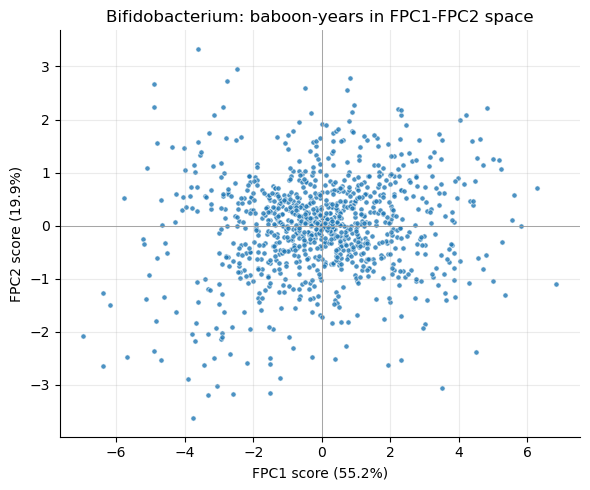

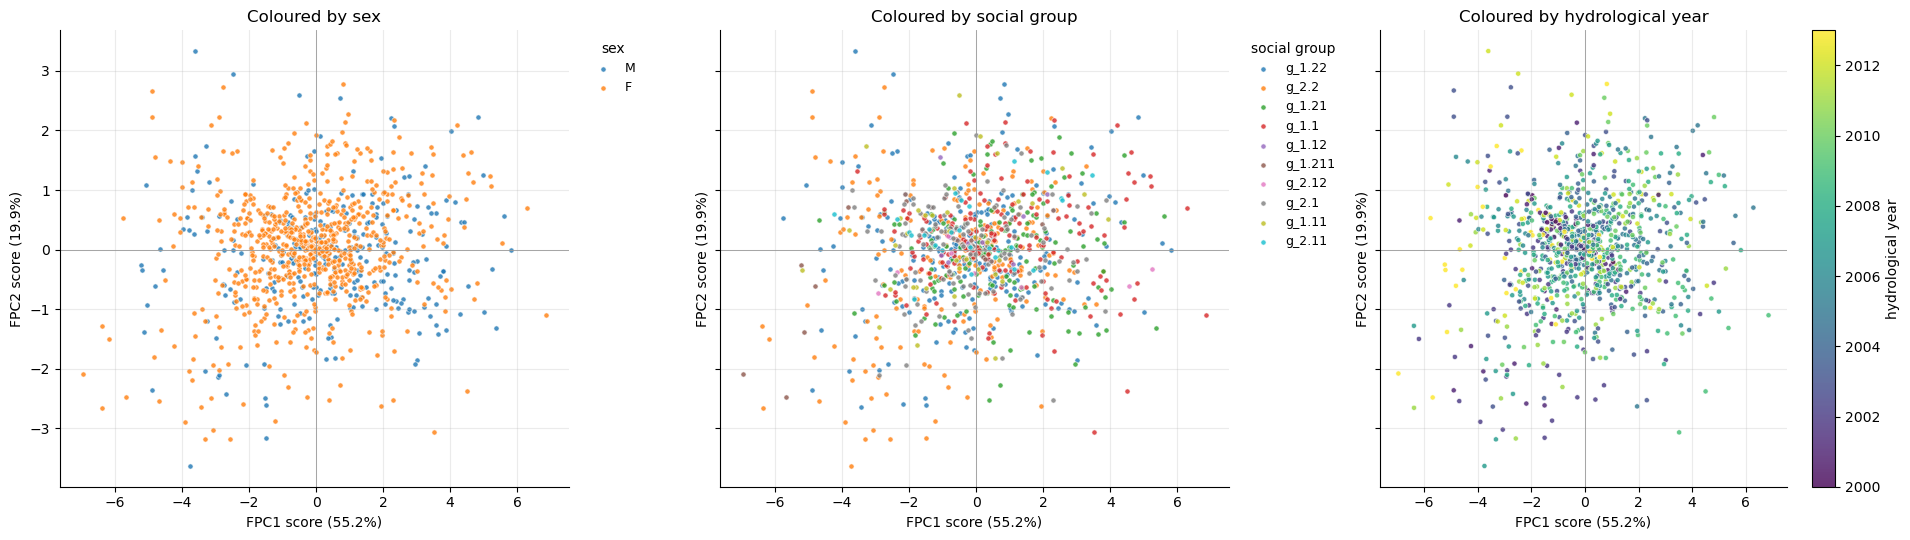

In [13]:
scores = pace.transform(curves)
axis_labels = dict(xlabel=f"FPC1 score ({fve[0]:.1f}%)", ylabel=f"FPC2 score ({fve[1]:.1f}%)")
curve_labels = {"sex": info["sex"], "social group": info["social_group"], "hydrological year": info["hydro_year"]}

plot_scores(scores, s=14, title=f"{SHORT[TAXON]}: baboon-years in FPC1-FPC2 space", figsize=(6, 5), **axis_labels)
plot_scores_by(scores, curve_labels, continuous=["hydrological year"], s=14, **axis_labels);

## 7. What structures the seasonal trajectories?

**Method.** With each curve reduced to a score vector, group differences can be tested with permutation tests on those vectors:
- **PERMANOVA** asks whether group centroids differ, i.e. whether the typical trajectory differs between groups;
- **PERMDISP** asks whether the groups differ in spread around their centroids. A significant PERMANOVA together with a significant PERMDISP may reflect unequal spread rather than shifted centroids.

Curves are not independent: each baboon contributes several years, and all baboons share each year. The permutation scheme must respect this design:

| Factor | Question | Permutation |
|---|---|---|
| Baboon | Does each baboon have its own seasonal signature (*idiosyncrasy*)? | baboon labels shuffled **within each year** |
| Hydrological year | Do all baboons shift together from year to year (*synchrony*)? | year labels shuffled **within each baboon** |
| Social group | Do baboons that live together share trajectories? | group labels shuffled **within each year** |
| Sex | Do males and females differ? | sex shuffled **between baboons**, keeping all of a baboon's years together |

**Using `fpca`.** `permanova(X, labels, blocks=None, scheme="free")` runs one test and returns a dict (`F`, `R2`, `p`, `PERMDISP_F`, `PERMDISP_p`, ...). `scheme` is `"free"`, `"within"` (shuffle within each block) or `"block"` (shuffle whole blocks). `permanova_table(X, tests)` runs several tests and returns a DataFrame, one row per test. Each test is the labels alone (free permutation) or a tuple `(labels, blocks, scheme)`. We use the table, on the first 3 scores.

In [14]:
K = 3
curve_tests = {
    "baboon": (info["baboon_id"], info["hydro_year"], "within"),
    "hydrological year": (info["hydro_year"], info["baboon_id"], "within"),
    "social group": (info["social_group"], info["hydro_year"], "within"),
    "sex": (info["sex"], info["baboon_id"], "block"),
}
permanova_table(scores[:, :K], curve_tests, n_perm=9999).round(3)

,groups,pseudo-F,R2,p (PERMANOVA),F (PERMDISP),p (PERMDISP)
test,,,,,,
baboon,100,4.284,0.308,0.000,2.083,0.000
hydrological year,14,12.399,0.134,0.000,3.235,0.000
social group,10,9.327,0.075,0.000,3.257,0.009
sex,2,11.448,0.011,0.056,7.583,0.053


## 8. Reconstructing individual curves

**Method.** A curve's smooth trajectory is the mean plus its scores times the eigenfunctions, $\hat X_i(t) = \hat\mu(t) + \sum_{k=1}^{K} \hat\xi_{ik}\,\hat\phi_k(t)$. With few samples, PACE shrinks the curve towards the mean rather than chasing every noisy point.

**Using `fpca`.** `model.reconstruct_curve(times, scores_i, n_components=K)` returns `(values, times_eval)`, the reconstruction on the model grid merged with `times`.

Below are four baboon-years with contrasting scores: the highest and lowest on FPC1 and on FPC2, among curves with at least 5 samples.

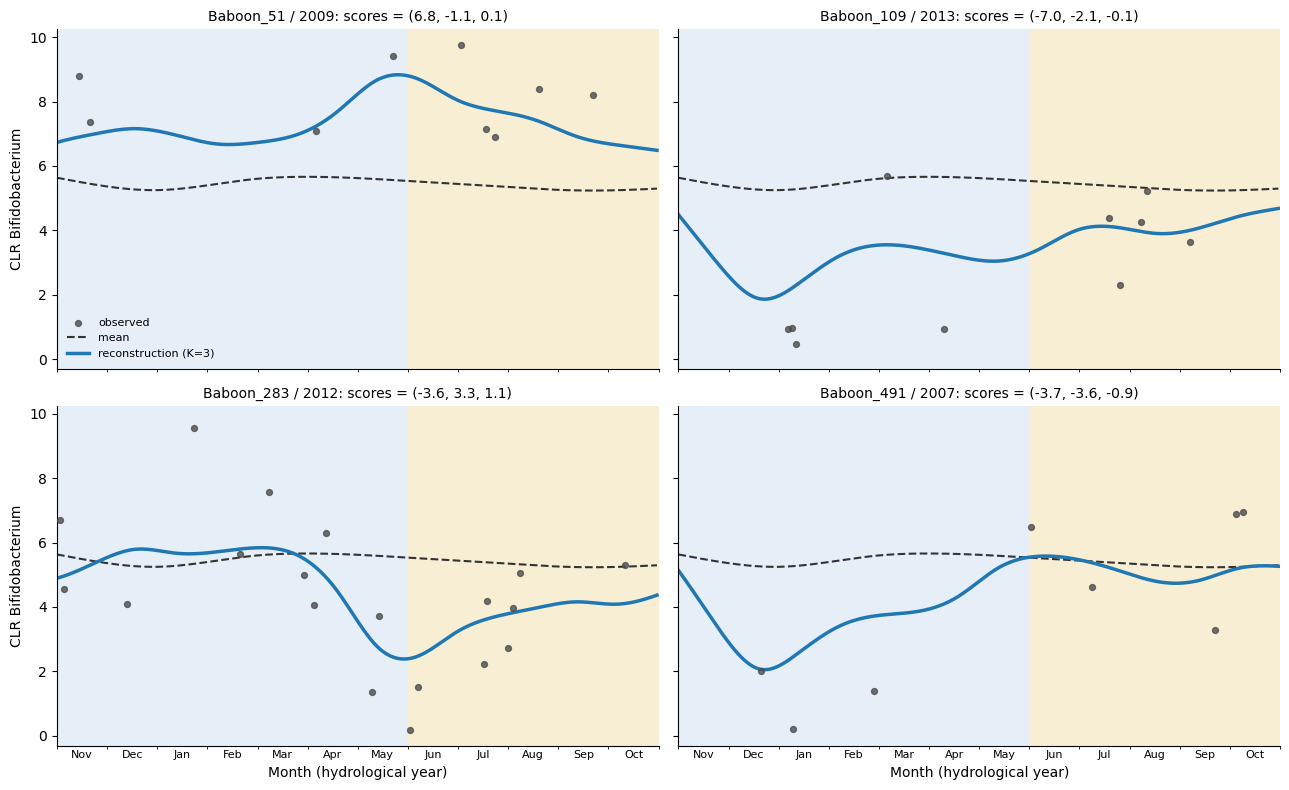

In [15]:
eligible = info["n_samples"].to_numpy() >= 5


def extreme_curves(S):
    # Four different curves: highest/lowest on component 1, then on component 2.
    picks = []
    for k, highest in [(0, True), (0, False), (1, True), (1, False)]:
        order = np.argsort(S[:, k])
        order = order[::-1] if highest else order
        picks.append(next(i for i in order if eligible[i] and i not in picks))
    return picks


fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True, sharey=True)
for ax, i in zip(axes.flat, extreme_curves(scores)):
    t, y = curves[i]
    recon, t_eval = pace.reconstruct_curve(t, scores[i], n_components=K)
    ax.scatter(t, y, s=18, color="0.3", alpha=0.8, label="observed", zorder=3)
    ax.plot(pace.grid_, pace.mean_values_, color="0.2", lw=1.5, ls="--", label="mean")
    ax.plot(t_eval, recon, color=colors[0], lw=2.5, label=f"reconstruction (K={K})")
    shade_seasons(ax)
    ax.set_title(f"{curve_ids[i]}: scores = ({', '.join(f'{s:.1f}' for s in scores[i, :K])})", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
for ax in axes[:, 0]:
    ax.set_ylabel(label)
for ax in axes[1]:
    ax.set_xlabel(XLABEL)
axes[0, 0].legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout()

## 9. Two-level FPCA with `TwoLevelPACE`

**Method.** Section 7 showed that a baboon's years resemble one another. Two-level FPCA (Di et al. 2009) builds that structure into the model. Curve $j$ of baboon $i$ is

$$X_{ij}(t) = \mu(t) + \eta_j(t) + Z_i(t) + W_{ij}(t) + \varepsilon_{ij}(t),$$

- $\eta_j(t)$ is a **visit effect**: a mean shift specific to visit $j$ and shared by all subjects. Here a visit is a hydrological year, so $\eta_j(t)$ would be that year's departure from the overall mean, common to all baboons. It is estimated as the average of all curves of visit $j$ minus $\mu(t)$. It is **not used by default**: $\eta_j(t) = 0$ unless visit effects are switched on (see below);
- $Z_i(t)$ is the baboon's **persistent** deviation, shared by all its years (level 1, between baboons);
- $W_{ij}(t)$ is that year's deviation from the baboon's own pattern (level 2, within baboon);
- $\varepsilon_{ij}(t)$ is measurement noise.

Each level has its own eigenfunctions ($\phi_k$ for level 1, $\psi_k$ for level 2) and scores. The split of variance between the levels measures how individual the trajectories are. We keep the default (no visit effects), so year effects shared by all baboons have no term of their own and appear at level 2. Switching $\eta_j(t)$ on would move the shared part of each year's shift into the mean, leaving level 2 for a baboon's own year-to-year changes.

**Using `fpca`.**
- `TwoLevelPACE(...).fit(curves, subject_ids)` takes the same curve list plus one subject label per curve (here the baboon). It stores `between_eigenvalues_` / `between_eigenfunctions_` for level 1 and `within_eigenvalues_` / `within_eigenfunctions_` for level 2, all on `grid_`. `mean_kwargs` configures the mean smoother, as in `PACE`.
- `transform(curves, subject_ids)` returns a dict:
  - `"between"`: one row per subject;
  - `"within"`: one row per curve;
  - `"subject_order"`: the subject label of each `"between"` row.
- `reconstruct(scores, subject_ids)` returns every curve on `grid_`.
- Visit effects are off by default (`visit_effects=False`). With `TwoLevelPACE(visit_effects=True)`, pass `visit_ids` (one visit label per curve, e.g. `info["hydro_year"]`) to `fit`, `transform` and `reconstruct`. The estimates are then stored in `visit_levels_` and `visit_effects_` (one row per visit, on `grid_`). Each subject may have at most one curve per visit.

In [17]:
baboon_of_curve = info["baboon_id"].to_numpy()

TWO_LEVEL_SETTINGS = dict(variance_threshold=1.0, n_segments=15,
                          mean_kwargs={"mean_penalty": 10.0, "ps_mean_n_segments": 12})
mlp = TwoLevelPACE(**TWO_LEVEL_SETTINGS).fit(curves, baboon_of_curve)
orient_eigenfunctions(mlp)

var_b, var_w = mlp.between_eigenvalues_.sum(), mlp.within_eigenvalues_.sum()
print(f"Noise variance {mlp.noise_variance_:.3f}")
print(f"Level 1 (between baboons): {len(mlp.between_eigenvalues_)} components, "
      f"{100 * var_b / (var_b + var_w):.1f}% of the retained variance")
print(f"Level 2 (within baboon):   {len(mlp.within_eigenvalues_)} components, "
      f"{100 * var_w / (var_b + var_w):.1f}% of the retained variance")

Noise variance 1.186
Level 1 (between baboons): 10 components, 29.5% of the retained variance
Level 2 (within baboon):   13 components, 70.5% of the retained variance


### 9.1 Eigenfunctions of each level

The top row shows how baboons differ persistently. The bottom row shows how one baboon's years differ from each other. Titles give each component's share of the variance of both levels together.

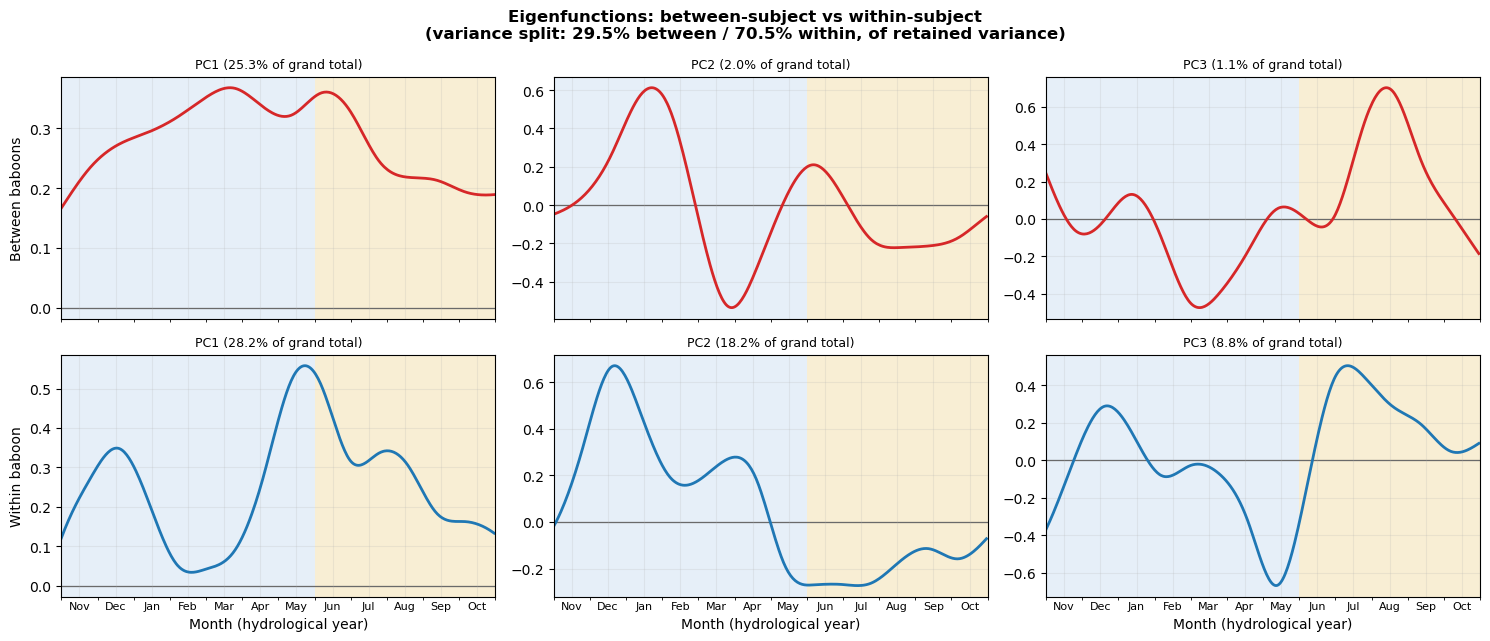

In [18]:
fig, axes = mlp.plot_eigenfunctions(n_between=3, n_within=3, figsize=(15, 6.5))
for ax in axes.flat:
    if ax.get_visible():
        shade_seasons(ax)
axes[0, 0].set_ylabel("Between baboons")
axes[1, 0].set_ylabel("Within baboon")
for ax in axes[1]:
    ax.set_xlabel(XLABEL)
fig.tight_layout()

### 9.2 Scores and tests at each level

Level 1 gives one score vector per **baboon**, and level 2 one per **baboon-year**. The permutation tests follow the design of each level:
- **Level 2** (one row per baboon-year): the four tests of section 7. All baboon identity should now sit in level 1, so a baboon effect at level 2 should vanish. A year effect should remain.
- **Level 1** (one row per baboon): only factors that describe a baboon, **sex** and **social group** (the group the baboon was sampled in most often over the study). Each baboon is one row, so labels are shuffled freely.

Level 2: within baboon (baboon-year scores)


,groups,pseudo-F,R2,p (PERMANOVA),F (PERMDISP),p (PERMDISP)
test,,,,,,
baboon,100,0.638,0.062,0.997,1.713,0.004
hydrological year,14,18.076,0.185,0.000,6.917,0.000
social group,10,5.588,0.046,0.030,6.900,0.000
sex,2,2.335,0.002,0.020,4.718,0.065


Level 1: between baboons (baboon scores)


,groups,pseudo-F,R2,p (PERMANOVA),F (PERMDISP),p (PERMDISP)
test,,,,,,
sex,2,3.636,0.036,0.054,0.051,0.833
social group,5,2.767,0.104,0.025,0.132,0.977


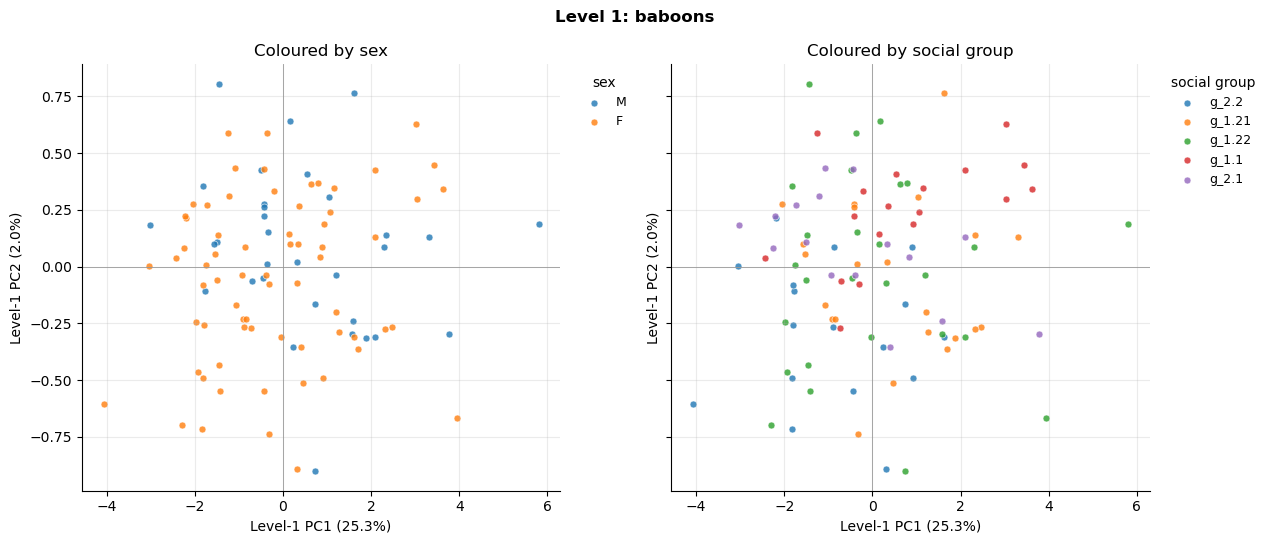

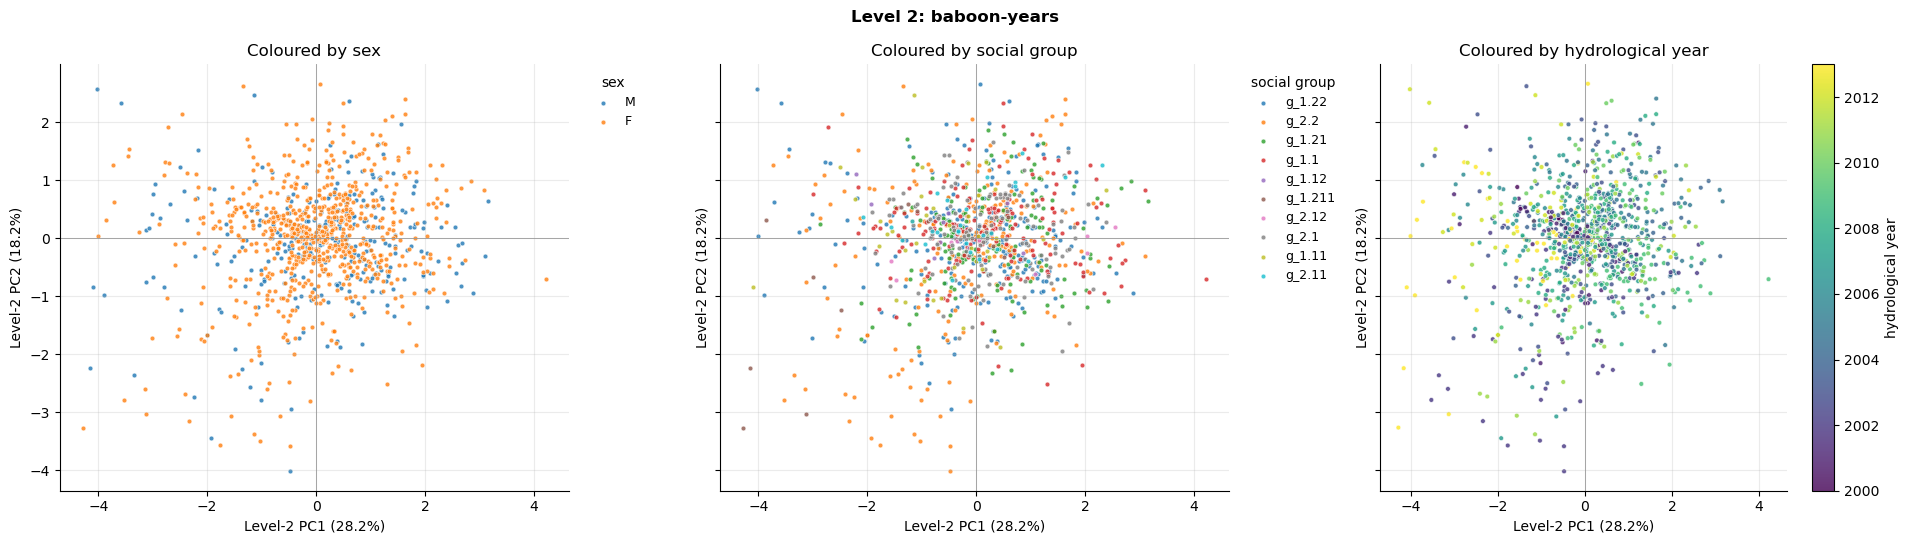

In [19]:
ml_scores = mlp.transform(curves, baboon_of_curve)
between = pd.DataFrame(ml_scores["between"], index=ml_scores["subject_order"])   # one row per baboon
within = ml_scores["within"]                                                       # one row per curve

baboon_sex = curve_info.groupby("baboon_id")["sex"].first().loc[between.index]
baboon_group = df.groupby("baboon_id")["social_group"].agg(lambda s: s.mode().iloc[0]).loc[between.index]
baboon_tests = {"sex": baboon_sex, "social group": baboon_group}

pct = 100 / (var_b + var_w)
plot_scores_by(between.to_numpy(), baboon_tests, s=25, title="Level 1: baboons",
               xlabel=f"Level-1 PC1 ({pct * mlp.between_eigenvalues_[0]:.1f}%)",
               ylabel=f"Level-1 PC2 ({pct * mlp.between_eigenvalues_[1]:.1f}%)")
plot_scores_by(within, curve_labels, continuous=["hydrological year"], s=12, title="Level 2: baboon-years",
               xlabel=f"Level-2 PC1 ({pct * mlp.within_eigenvalues_[0]:.1f}%)",
               ylabel=f"Level-2 PC2 ({pct * mlp.within_eigenvalues_[1]:.1f}%)")

print("Level 2: within baboon (baboon-year scores)")
display(permanova_table(within[:, :K], curve_tests, n_perm=9999).round(3))
print("Level 1: between baboons (baboon scores)")
display(permanova_table(between.to_numpy()[:, :K], baboon_tests, n_perm=9999).round(3))

### 9.3 One baboon across years

A two-level reconstruction of a well-sampled baboon. In every panel:
- the dashed line is the population mean $\mu(t)$;
- the red line is the baboon's persistent trajectory $\mu(t) + Z_i(t)$, the same in every year;
- the blue line is that year's trajectory $\mu(t) + Z_i(t) + W_{ij}(t)$, from `reconstruct`.

The gap between red and dashed is what is individual about this baboon. The gap between blue and red is what is particular to that year. The baboon shown is the one with the largest level-1 PC1 score among baboons with at least 4 well-sampled years.

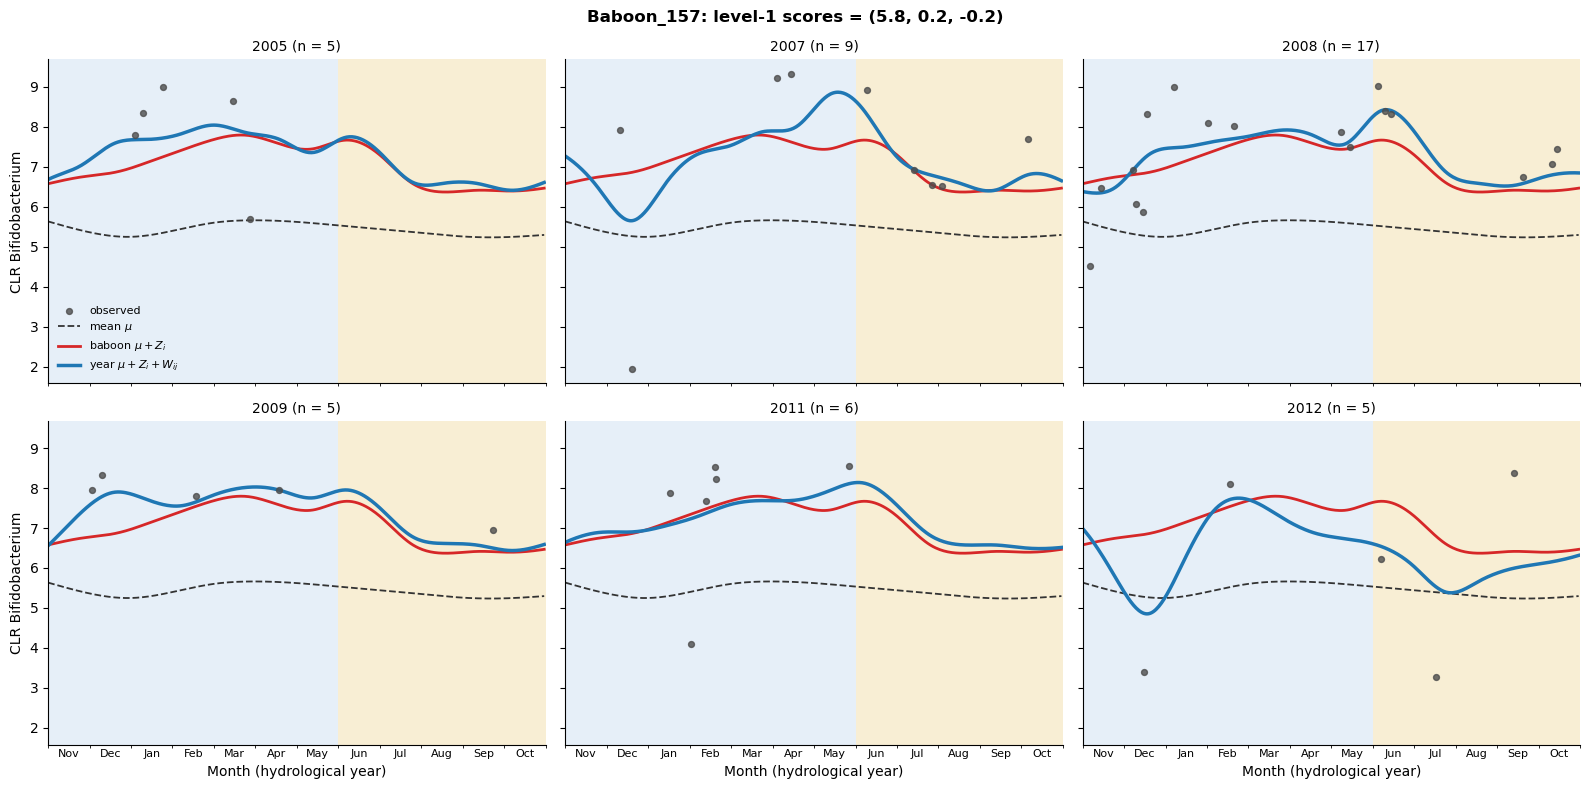

In [20]:
recon_all = mlp.reconstruct(ml_scores, baboon_of_curve)          # (n_curves, len(grid_))

n_good_years = info[eligible].groupby("baboon_id").size()
candidates = n_good_years[n_good_years >= 4].index
bid = between.loc[candidates, 0].abs().idxmax()
rows_b = [r for r in np.where(baboon_of_curve == bid)[0]]
rows_b = sorted(sorted(rows_b, key=lambda r: -info["n_samples"].iloc[r])[:6], key=lambda r: info["hydro_year"].iloc[r])
persistent = mlp.mean_values_ + between.loc[bid].to_numpy() @ mlp.between_eigenfunctions_

fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True, sharey=True)
for ax, r in zip(axes.flat, rows_b):
    t, y = curves[r]
    ax.scatter(t, y, s=18, color="0.3", alpha=0.8, label="observed", zorder=3)
    ax.plot(mlp.grid_, mlp.mean_values_, color="0.2", lw=1.3, ls="--", label=r"mean $\mu$")
    ax.plot(mlp.grid_, persistent, color="tab:red", lw=2, label=r"baboon $\mu + Z_i$")
    ax.plot(mlp.grid_, recon_all[r], color="tab:blue", lw=2.5, label=r"year $\mu + Z_i + W_{ij}$")
    shade_seasons(ax)
    ax.set_title(f"{info['hydro_year'].iloc[r]} (n = {len(t)})", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
for ax in axes.flat[len(rows_b):]:
    ax.set_visible(False)
for ax in axes[:, 0]:
    ax.set_ylabel(label)
for ax in axes[1]:
    ax.set_xlabel(XLABEL)
axes[0, 0].legend(frameon=False, fontsize=8, loc="lower left")
fig.suptitle(f"{bid}: level-1 scores = ({', '.join(f'{s:.1f}' for s in between.loc[bid].to_numpy()[:K])})",
             fontweight="bold")
fig.tight_layout()

## 10. Multivariate FPCA with `MFPCA`

**Method.** The six genera are measured on the same samples, so we can think of each baboon-year as a **six-dimensional curve**. Multivariate FPCA (Happ & Greven 2018) finds components of *joint* variation: a multivariate eigenfunction is a set of six curves, one per genus, that vary together. It works in three steps:
1. fit a univariate PACE model to each genus;
2. divide each genus's scores by its total standard deviation, so that every genus has unit total variance, and concatenate them;
3. run an ordinary PCA on the concatenated scores. Each loading vector maps back to one function per genus.

**Using `fpca`.** `MFPCA(models, feature_names=...)` takes a dict of fitted univariate models, one per feature. There are two ways to fit it:
- **from curves:** `mfpca.fit(data)`, where `data = {feature: curves}` holds every feature's curves, aligned by position (row $i$ is the same unit in every feature). `MFPCA` computes the univariate scores itself with each model's `transform`, and `mfpca.transform(data)` scores data in the same format. This is the path for univariate `PACE` models, and the one we use here.
- **from scores:** `mfpca.fit_from_scores(scores)`, where `scores = {feature: score matrix}`. Use this when the univariate scores come from elsewhere, for example from one level of a two-level model (section 11). Score new data with `mfpca.transform_from_scores(scores)`. Both paths give the same fit for `PACE` models:

```python
univariate = {g: pace_models[g].transform(curves_by_taxon[g]) for g in top_taxa}
mfpca_b = MFPCA(pace_models, feature_names=top_taxa).fit_from_scores(univariate)
mv_scores_b = mfpca_b.transform_from_scores(univariate)       # same as mfpca.transform(curves_by_taxon)
```

The fitted model stores the multivariate eigenvalues and `explained_variance_ratio_`. `get_feature_weight_function(feature)` returns one feature's part of the eigenfunctions. With `scale_features=True` (the default) they are in the scaled space, where genera are comparable. `orient_eigenfunctions(mfpca)` fixes the signs as for `PACE`.

We first fit one PACE model per genus, with the same settings as in section 4.

In [38]:
curves_by_taxon = {}
for taxon in top_taxa:
    ids_t, curves_t = curves_from_long(clr_df, value_col=taxon, curve_col="curve", time_col="t")
    assert ids_t == curve_ids          # same curves, in the same order, for every genus
    curves_by_taxon[taxon] = curves_t

pace_models = {taxon: orient_eigenfunctions(PACE(**PACE_SETTINGS).fit(curves_by_taxon[taxon]))
               for taxon in top_taxa}

pd.DataFrame({SHORT[t]: {"components": m.n_components_available_,
                         "FPC1 %": 100 * explained_variance_ratio(m)[0],
                         "FPC2 %": 100 * explained_variance_ratio(m)[1],
                         "noise / total variance": m.noise_variance_ / clr_df[t].var()}
              for t, m in pace_models.items()}).T.round(2)

,components,FPC1 %,FPC2 %,noise / total variance
Bifidobacterium,13.0,55.16,19.94,0.56
Prevotella_9,14.0,61.25,13.11,0.56
Rikenellaceae_RC9,13.0,54.86,15.44,0.49
Ca. Methanogranum,12.0,61.50,13.07,0.54
Megasphaera,11.0,51.00,26.34,0.55
Dialister,12.0,55.22,17.16,0.77


### 10.1 Univariate eigenfunctions

The first two eigenfunctions of each genus, as in section 5.

**Using `fpca`.** `plot_feature_eigenfunctions(models, n_components=2)` draws one column per model and one row per component. Any fitted model with `grid_`, `eigenvalues_` and `eigenfunction_values_` works, including one level of a two-level model (section 11).

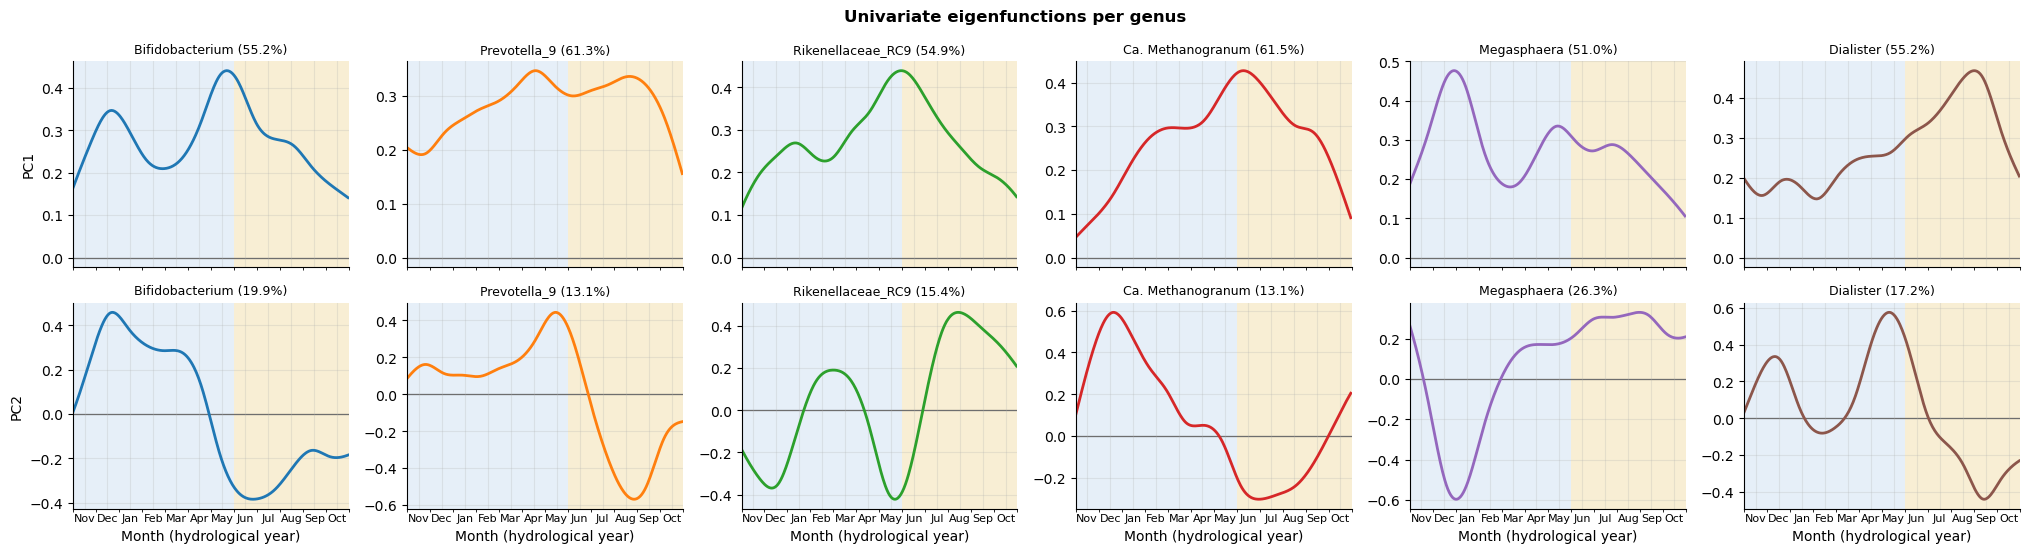

In [22]:
fig, axes = plot_feature_eigenfunctions(pace_models, n_components=2, labels=SHORT, colors=TAXON_COLORS,
                                        xlabel=XLABEL, title="Univariate eigenfunctions per genus")
for ax in axes.flat:
    shade_seasons(ax)
fig.tight_layout()

### 10.2 Multivariate eigenfunctions

Each panel is one multivariate component, and the six coloured curves are its eigenfunction for each genus. Curves with the same sign rise and fall together in that component; curves of opposite sign trade off against each other.

**Using `fpca`.** `plot_mfpca_eigenfunctions(mfpca, n_components=3, n_cols=1)` draws one panel per component with all features overlaid. Titles give each component's share and the cumulative share.

Variance explained (%): [41.1 18.1  7.8  5.2  4.5  3.8]


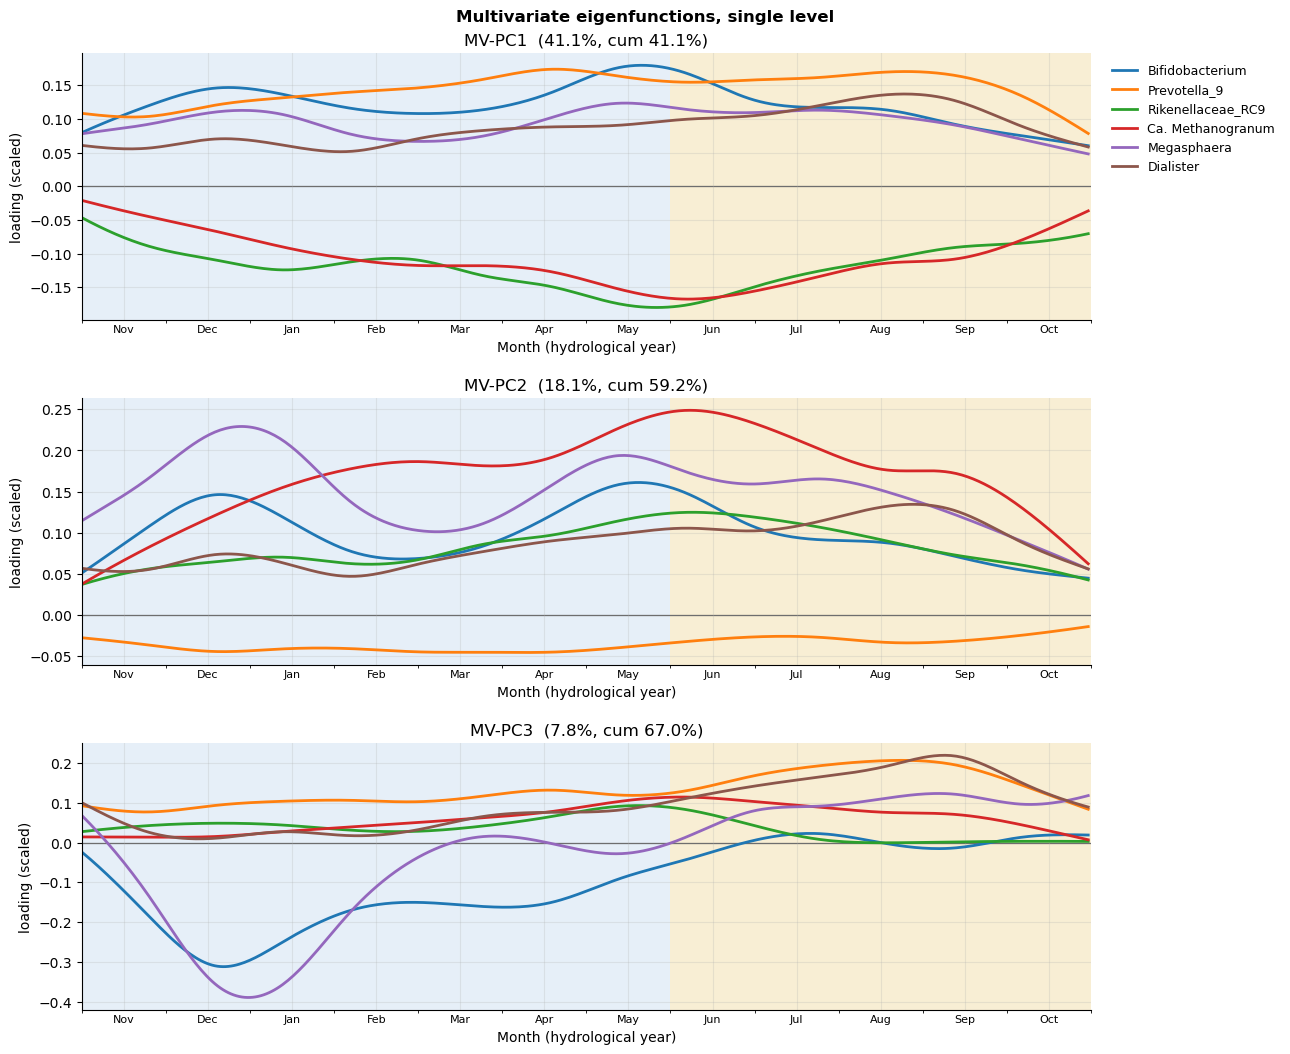

In [27]:
mfpca = MFPCA(pace_models, feature_names=top_taxa, method="happ_greven").fit(curves_by_taxon)
orient_eigenfunctions(mfpca)
mv_scores = mfpca.transform(curves_by_taxon)               # (n_curves, n_components)
mv_evr = 100 * mfpca.explained_variance_ratio_
print("Variance explained (%):", np.round(mv_evr[:6], 1))

fig, axes = plot_mfpca_eigenfunctions(mfpca, n_components=3, n_cols=1, labels=SHORT, colors=TAXON_COLORS,
                                      xlabel=XLABEL, title="Multivariate eigenfunctions, single level")
for ax in axes:
    shade_seasons(ax)

### 10.3 Scores and tests

As in sections 6–7, now for the multivariate scores.

,groups,pseudo-F,R2,p (PERMANOVA),F (PERMDISP),p (PERMDISP)
test,,,,,,
baboon,100,6.046,0.386,0.000,2.317,0.000
hydrological year,14,14.087,0.150,0.000,3.747,0.000
social group,10,11.950,0.094,0.000,2.844,0.003
sex,2,5.200,0.005,0.262,16.341,0.034


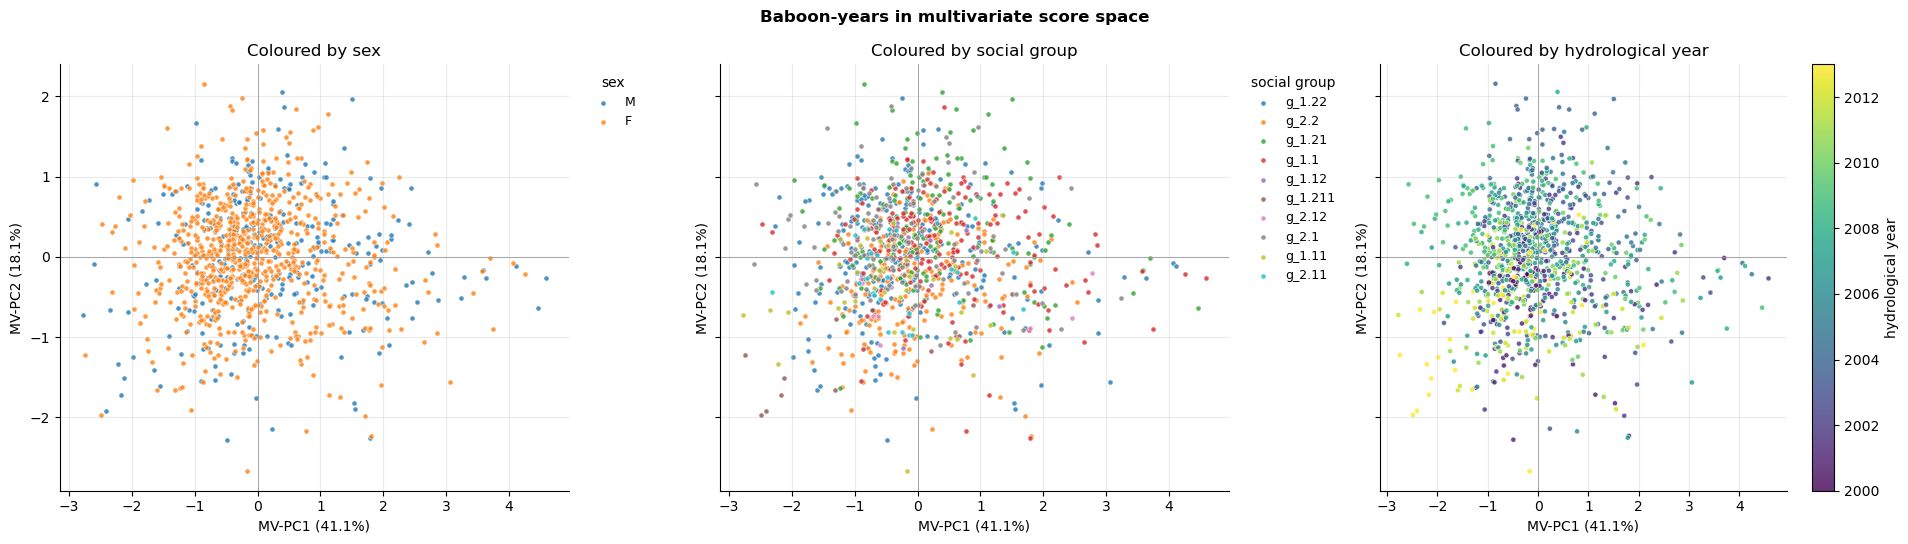

In [30]:
mv_axis_labels = dict(xlabel=f"MV-PC1 ({mv_evr[0]:.1f}%)", ylabel=f"MV-PC2 ({mv_evr[1]:.1f}%)")
plot_scores_by(mv_scores, curve_labels, continuous=["hydrological year"], s=14,
               title="Baboon-years in multivariate score space", **mv_axis_labels)
permanova_table(mv_scores[:, :K], curve_tests, n_perm=9999).round(3)

### 10.4 Reconstructions

**Using `fpca`.** `mfpca.reconstruct_feature(mv_scores_i, feature, which_components=K)` returns one feature's curve, reconstructed from the multivariate scores, together with its grid. `mfpca.inverse_transform_scores(mv_scores, K)` gives the matching univariate scores of every feature.

Each row below is one of the baboon-years with the highest and lowest scores on MV-PC1 and MV-PC2, with all six genera reconstructed from 3 multivariate components. Dashed lines are the means.

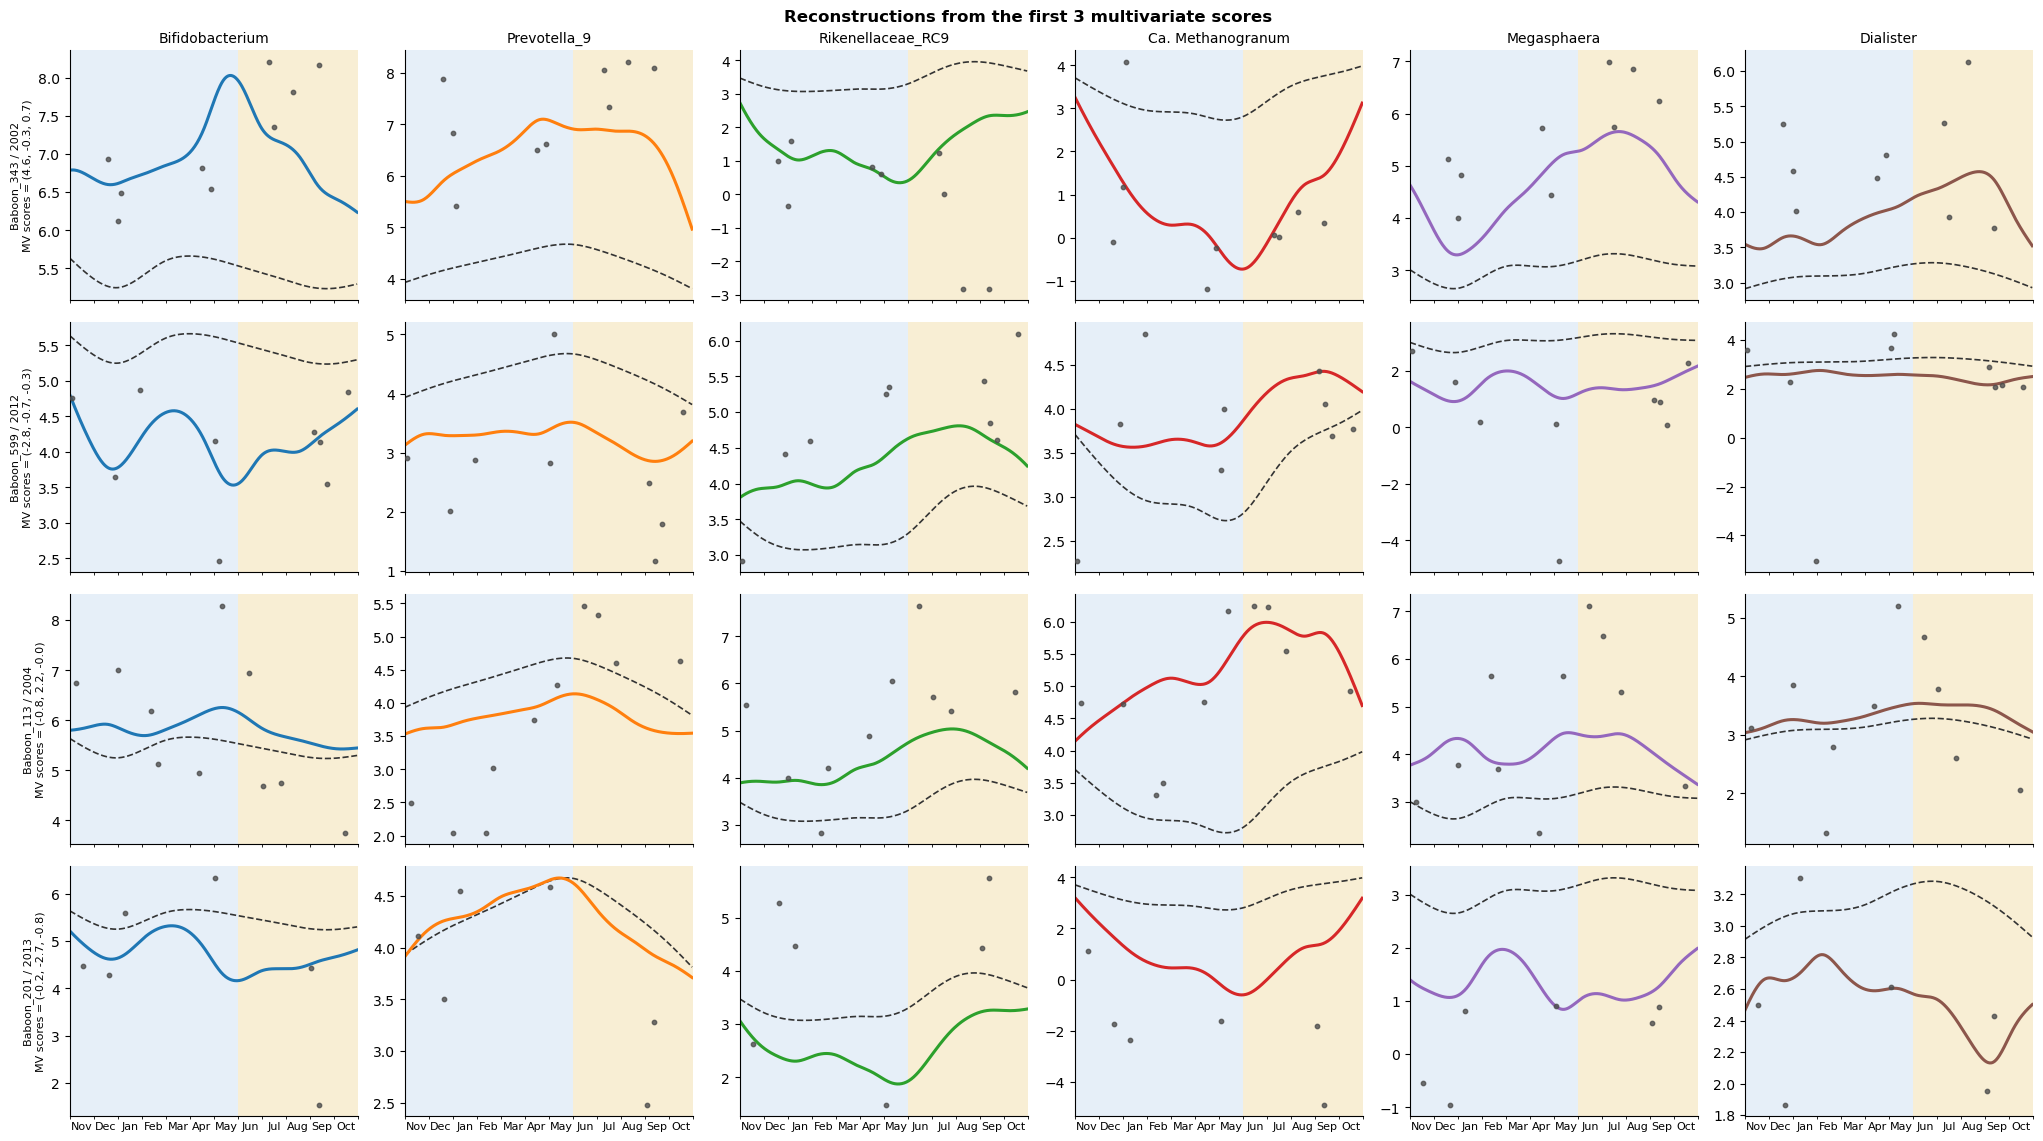

In [25]:
picks_mv = extreme_curves(mv_scores)
fig, axes = plt.subplots(len(picks_mv), N_TAXA, figsize=(3.4 * N_TAXA, 2.9 * len(picks_mv)), sharex=True)
for r, i in enumerate(picks_mv):
    for c, taxon in enumerate(top_taxa):
        ax, p = axes[r, c], pace_models[taxon]
        t, y = curves_by_taxon[taxon][i]
        recon, grid_t = mfpca.reconstruct_feature(mv_scores[i], taxon, which_components=K)
        ax.scatter(t, y, s=10, color="0.3", alpha=0.8, zorder=3)
        ax.plot(p.grid_, p.mean_values_, color="0.2", lw=1.2, ls="--")
        ax.plot(grid_t, recon, color=TAXON_COLORS[taxon], lw=2.2)
        shade_seasons(ax)
        ax.spines[["top", "right"]].set_visible(False)
        if r == 0:
            ax.set_title(SHORT[taxon], fontsize=10)
    axes[r, 0].set_ylabel(f"{curve_ids[i]}\nMV scores = ({', '.join(f'{s:.1f}' for s in mv_scores[i, :K])})",
                          fontsize=8)
fig.suptitle(f"Reconstructions from the first {K} multivariate scores", fontweight="bold")
fig.tight_layout()

## 11. Multilevel multivariate FPCA

**Method.** We combine the two approaches: a two-level model for each genus (as in section 9), followed by the Happ–Greven step **separately at each level**:
- **Level 1 (between baboons):** a joint PCA of the six genera's level-1 scores, one row per baboon. Its components describe how baboons differ persistently across all six genera at once.
- **Level 2 (within baboon):** a joint PCA of the level-2 scores, one row per baboon-year. Its components describe how a baboon's years differ from its "typical" year across the six genera at once.

At each level, every genus is scaled to unit total variance using that level's eigenvalues.

**Using `fpca`.** A two-level model cannot score curves level by level, so here MFPCA is fitted **from scores**:
1. `two_level_model.level_model("between")` (or `"within"`) returns one level as a small model with the attributes `MFPCA` reads: `grid_`, `mean_values_` (the mean $\mu$ for level 1, zero for level 2), `eigenvalues_` and `eigenfunction_values_`;
2. `MFPCA({genus: level model}).fit_from_scores({genus: that level's scores})` fits the level;
3. `transform_from_scores` returns the multivariate scores, and the plotting, orientation and reconstruction functions work as in section 10.

In [31]:
ml_models, ml_scores_by_taxon = {}, {}
for taxon in top_taxa:
    m = orient_eigenfunctions(TwoLevelPACE(**TWO_LEVEL_SETTINGS).fit(curves_by_taxon[taxon], baboon_of_curve))
    ml_models[taxon] = m
    ml_scores_by_taxon[taxon] = m.transform(curves_by_taxon[taxon], baboon_of_curve)
    assert list(ml_scores_by_taxon[taxon]["subject_order"]) == list(between.index)

level1 = {t: m.level_model("between") for t, m in ml_models.items()}
level2 = {t: m.level_model("within") for t, m in ml_models.items()}
scores1 = {t: s["between"] for t, s in ml_scores_by_taxon.items()}   # (n_baboons, N1) per genus
scores2 = {t: s["within"] for t, s in ml_scores_by_taxon.items()}    # (n_curves, N2) per genus

pd.DataFrame({SHORT[t]: {"level-1 components": len(m.between_eigenvalues_),
                         "level-2 components": len(m.within_eigenvalues_),
                         "level-1 share %": 100 * m.between_eigenvalues_.sum()
                         / (m.between_eigenvalues_.sum() + m.within_eigenvalues_.sum()),
                         "noise variance": m.noise_variance_}
              for t, m in ml_models.items()}).T.round(2)

,level-1 components,level-2 components,level-1 share %,noise variance
Bifidobacterium,10.0,13.0,29.53,1.19
Prevotella_9,9.0,13.0,43.78,0.82
Rikenellaceae_RC9,11.0,11.0,30.46,1.13
Ca. Methanogranum,9.0,12.0,36.03,1.95
Megasphaera,9.0,10.0,21.84,1.26
Dialister,9.0,12.0,31.22,0.72


### 11.1 Univariate eigenfunctions at each level

The first two eigenfunctions of each genus at each level. Here the percentages are shares within that level.

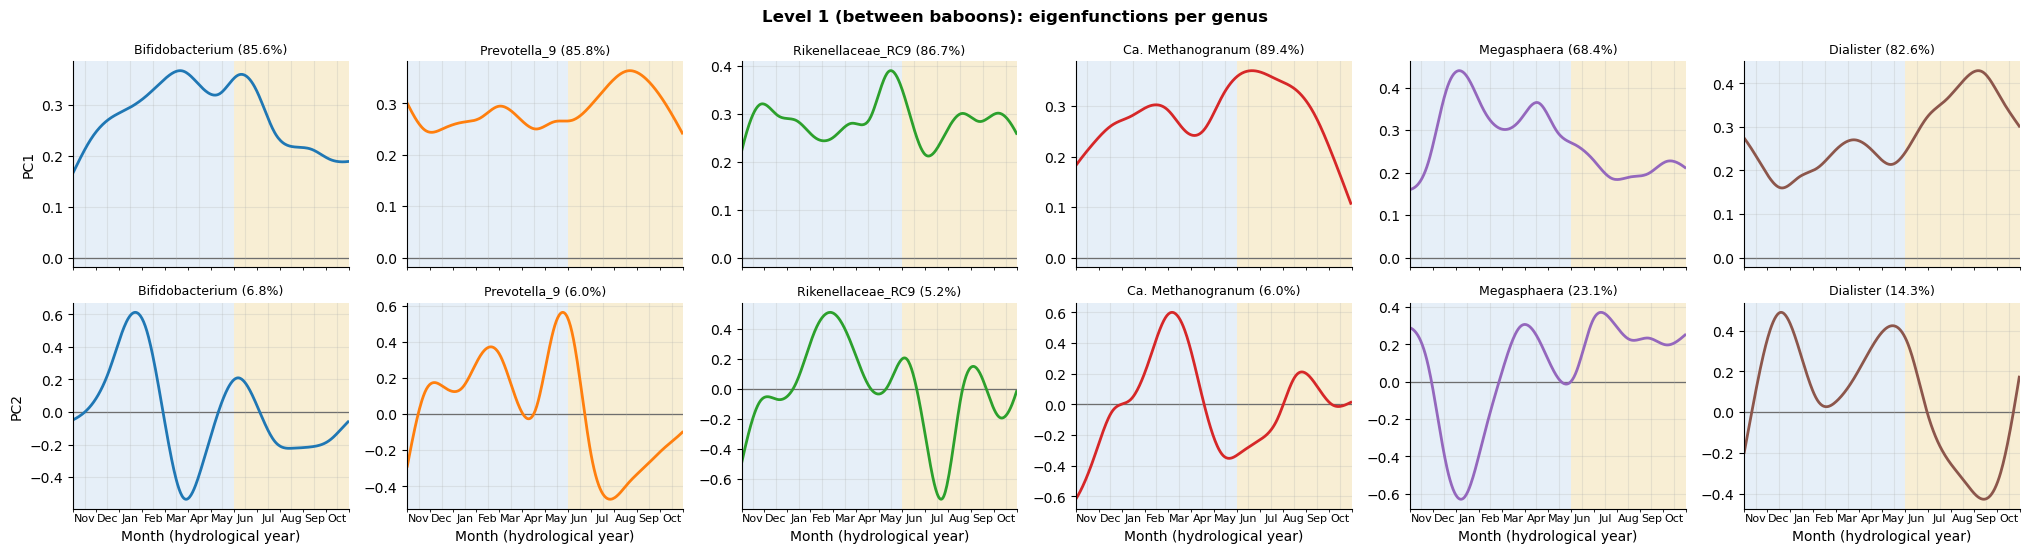

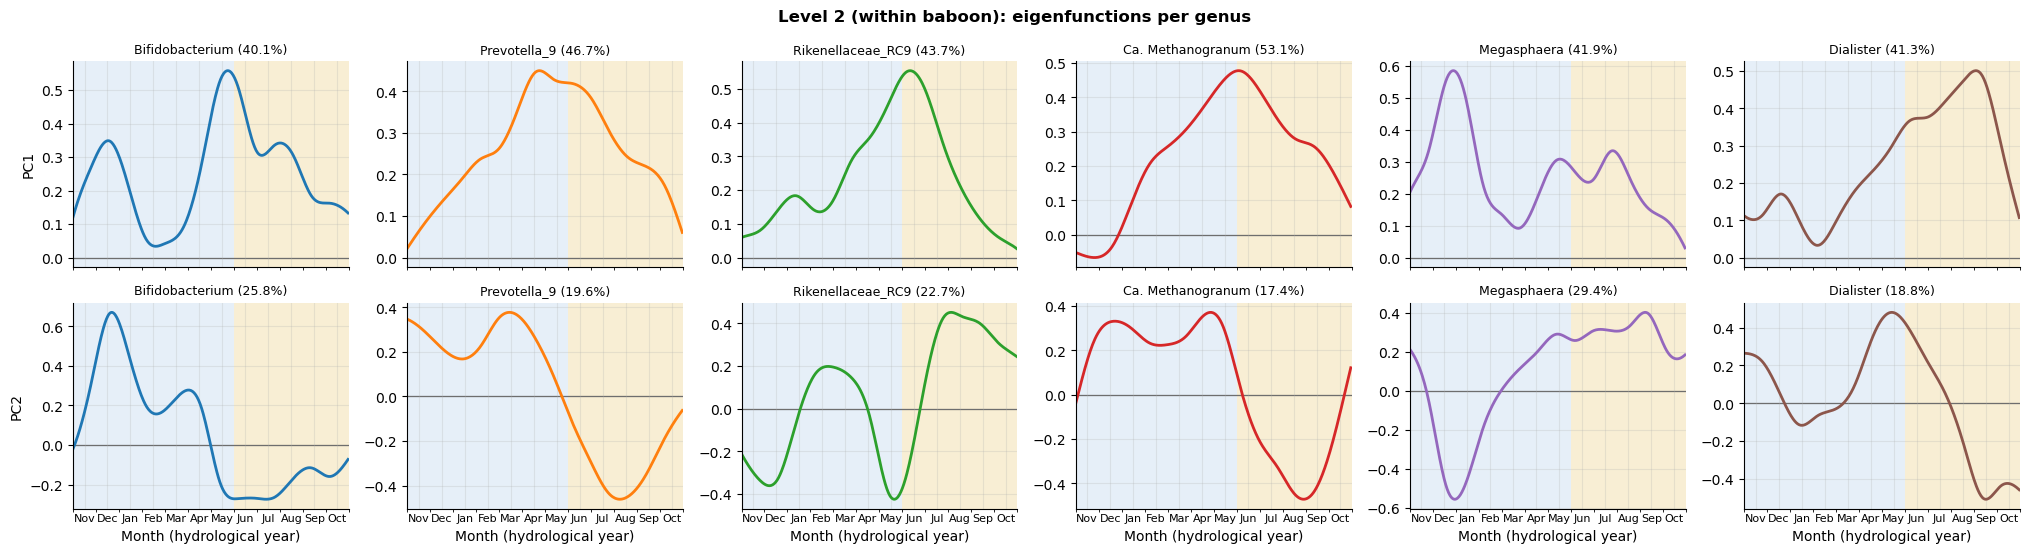

In [32]:
for name, models in [("Level 1 (between baboons)", level1), ("Level 2 (within baboon)", level2)]:
    fig, axes = plot_feature_eigenfunctions(models, n_components=2, labels=SHORT, colors=TAXON_COLORS,
                                            xlabel=XLABEL, title=f"{name}: eigenfunctions per genus")
    for ax in axes.flat:
        if ax.get_visible():
            shade_seasons(ax)
    fig.tight_layout()

### 11.2 Multivariate eigenfunctions at each level

Level 1 (between baboons): variance explained (%) [69.4 11.2  5.   4.1  2.7]
Level 2 (within baboon): variance explained (%) [23.2 19.2 10.   6.3  5.5]


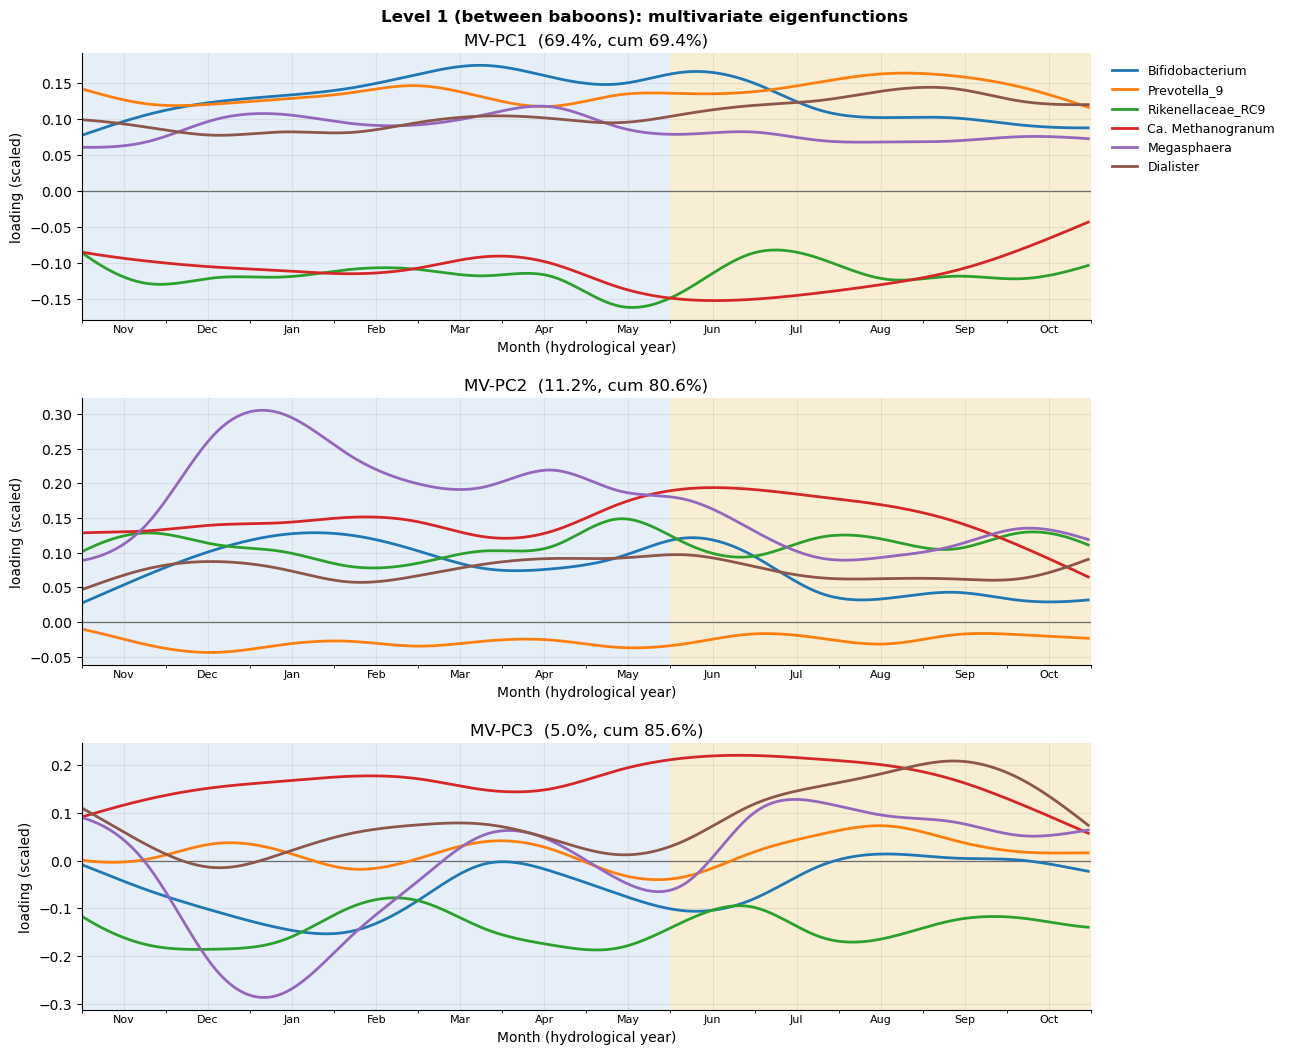

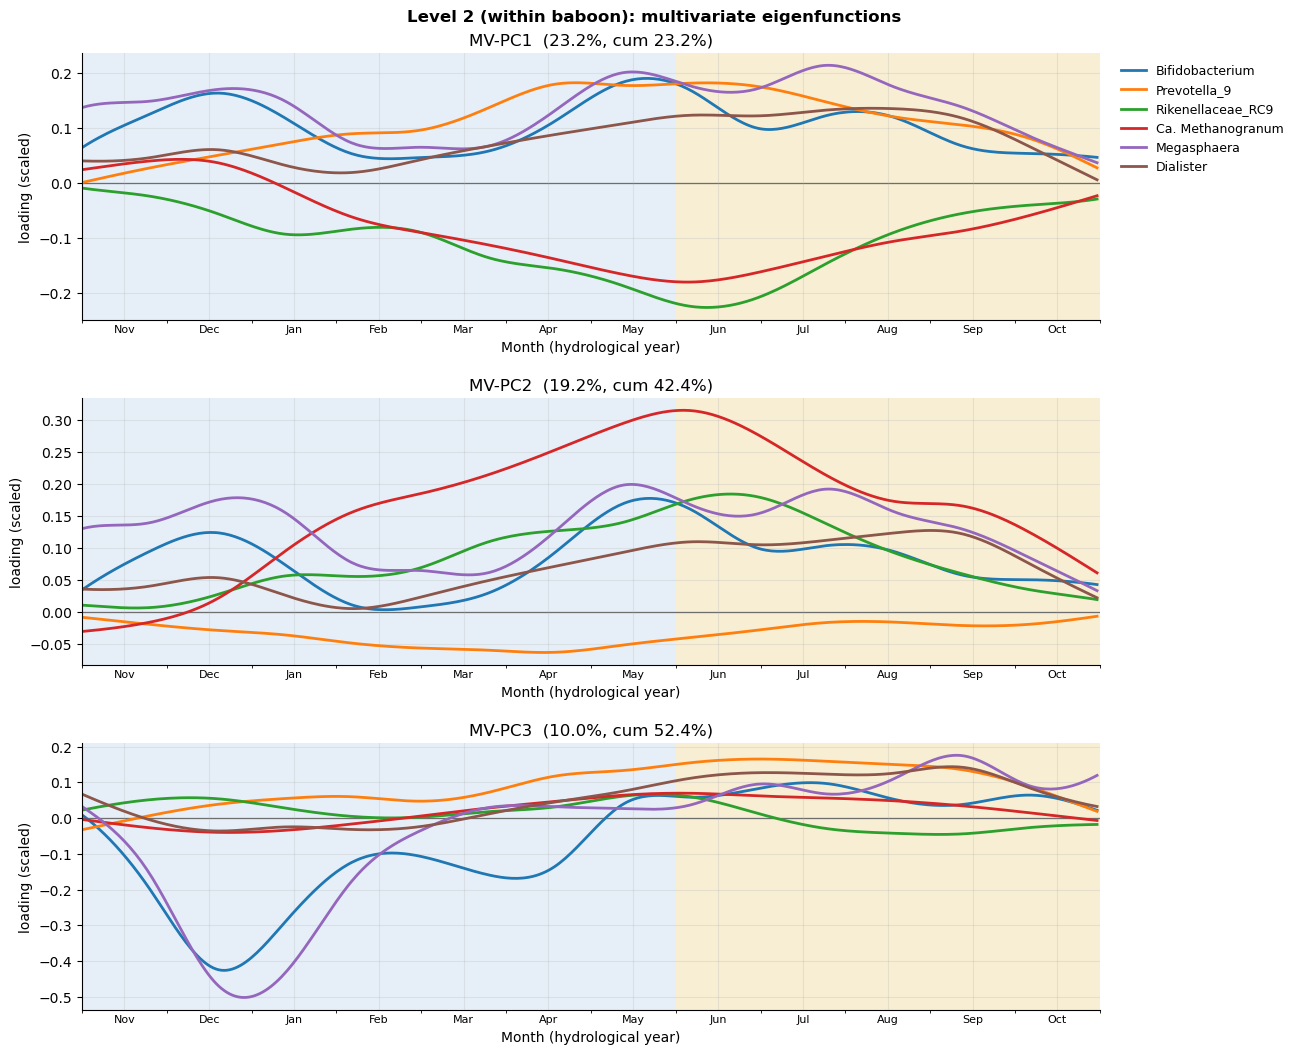

In [33]:
mfpca1 = orient_eigenfunctions(MFPCA(level1, feature_names=top_taxa).fit_from_scores(scores1))
mfpca2 = orient_eigenfunctions(MFPCA(level2, feature_names=top_taxa).fit_from_scores(scores2))
S1 = mfpca1.transform_from_scores(scores1)        # one row per baboon
S2 = mfpca2.transform_from_scores(scores2)        # one row per baboon-year

for name, mv in [("Level 1 (between baboons)", mfpca1), ("Level 2 (within baboon)", mfpca2)]:
    print(f"{name}: variance explained (%) {np.round(100 * mv.explained_variance_ratio_[:5], 1)}")
    fig, axes = plot_mfpca_eigenfunctions(mv, n_components=3, n_cols=1, labels=SHORT, colors=TAXON_COLORS,
                                          xlabel=XLABEL, title=f"{name}: multivariate eigenfunctions")
    for ax in axes:
        shade_seasons(ax)

### 11.3 Scores and tests at each level

As in section 9.2, now for the multivariate scores of each level.

Level 2: within baboon (multivariate baboon-year scores)


,groups,pseudo-F,R2,p (PERMANOVA),F (PERMDISP),p (PERMDISP)
test,,,,,,
baboon,100,0.515,0.051,1.000,1.721,0.002
hydrological year,14,28.261,0.261,0.000,3.925,0.000
social group,10,8.209,0.066,0.001,2.251,0.016
sex,2,0.602,0.001,0.322,8.723,0.020


Level 1: between baboons (multivariate baboon scores)


,groups,pseudo-F,R2,p (PERMANOVA),F (PERMDISP),p (PERMDISP)
test,,,,,,
sex,2,1.844,0.018,0.156,2.497,0.162
social group,5,2.543,0.097,0.024,0.532,0.801


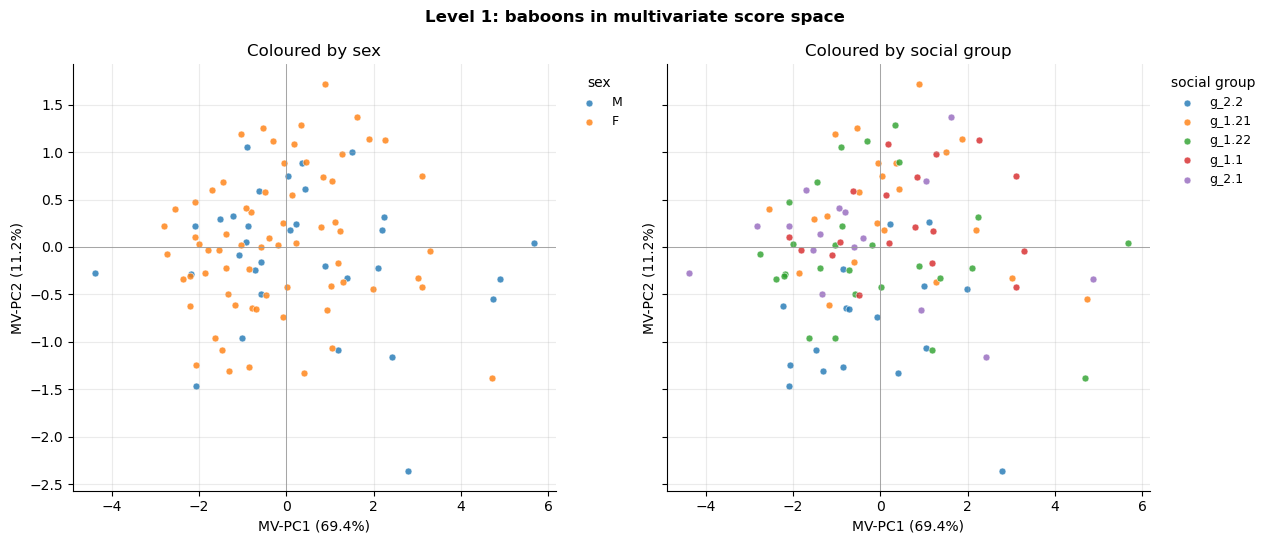

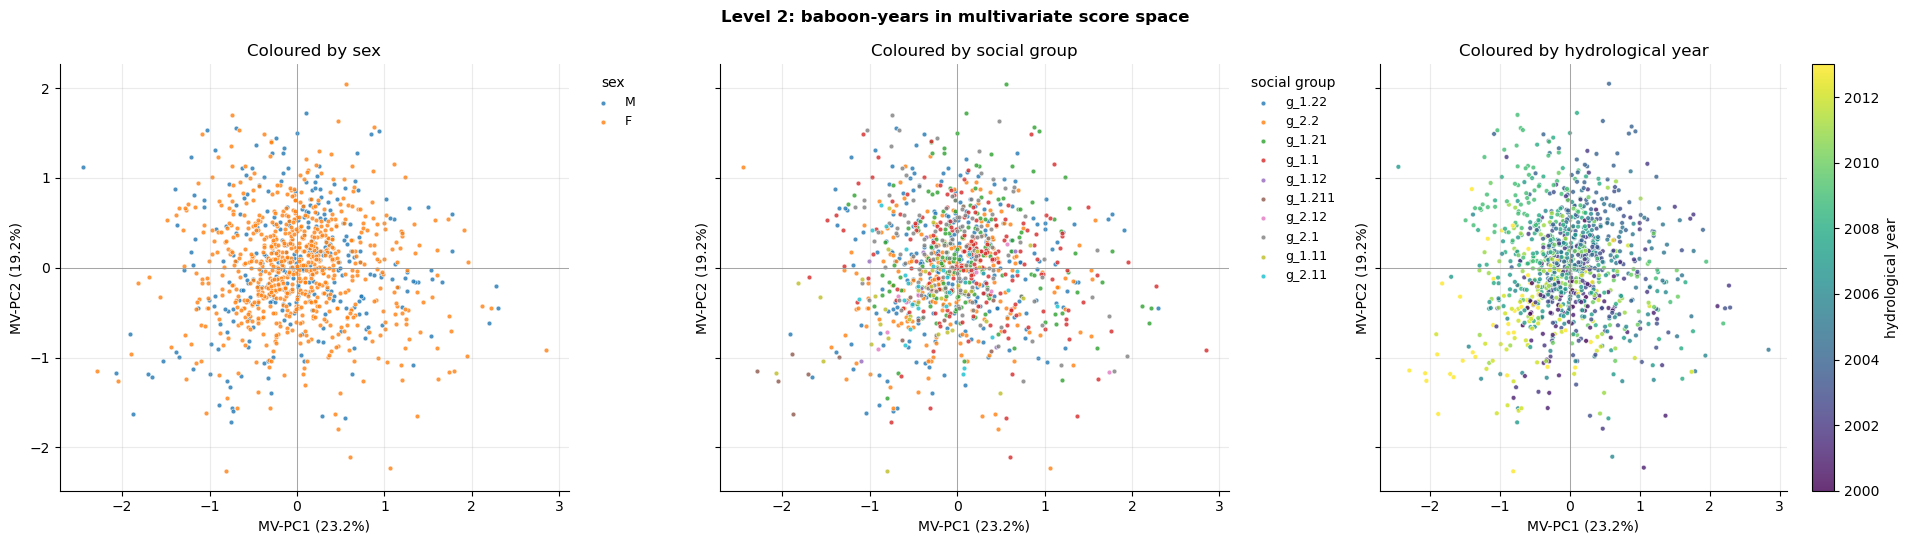

In [34]:
evr1, evr2 = 100 * mfpca1.explained_variance_ratio_, 100 * mfpca2.explained_variance_ratio_
plot_scores_by(S1, baboon_tests, s=25, title="Level 1: baboons in multivariate score space",
               xlabel=f"MV-PC1 ({evr1[0]:.1f}%)", ylabel=f"MV-PC2 ({evr1[1]:.1f}%)")
plot_scores_by(S2, curve_labels, continuous=["hydrological year"], s=12,
               title="Level 2: baboon-years in multivariate score space",
               xlabel=f"MV-PC1 ({evr2[0]:.1f}%)", ylabel=f"MV-PC2 ({evr2[1]:.1f}%)")

print("Level 2: within baboon (multivariate baboon-year scores)")
display(permanova_table(S2[:, :K], curve_tests, n_perm=9999).round(3))
print("Level 1: between baboons (multivariate baboon scores)")
display(permanova_table(S1[:, :K], baboon_tests, n_perm=9999).round(3))

### 11.4 One baboon in one year

The baboon of section 9.3 in its best-sampled year, for all six genera, reconstructed from the first 3 multivariate components of each level:
- dashed: the population mean;
- black: the baboon's persistent trajectory (level 1);
- coloured: that year's trajectory (level 1 + level 2).

**Using `fpca`.** `inverse_transform_scores(S, K)` maps multivariate scores back to each genus's univariate scores at that level. The level model's `reconstruct_curve(times, scores)` then gives its contribution: mean plus scores times eigenfunctions, with a zero mean for level 2.

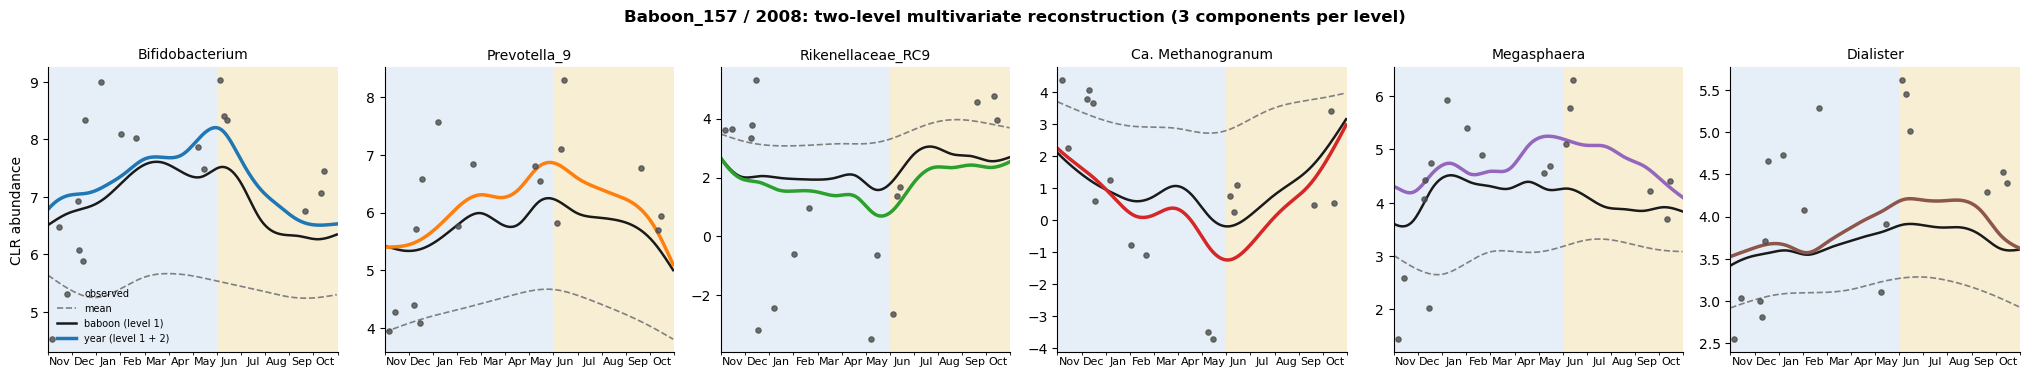

In [35]:
b_idx = list(between.index).index(bid)
r_best = max(rows_b, key=lambda r: info["n_samples"].iloc[r])
xi_hat = mfpca1.inverse_transform_scores(S1[b_idx], K)       # genus -> level-1 scores of this baboon
zeta_hat = mfpca2.inverse_transform_scores(S2[r_best], K)    # genus -> level-2 scores of this year

fig, axes = plt.subplots(1, N_TAXA, figsize=(3.4 * N_TAXA, 3.8), sharex=True)
for ax, taxon in zip(axes, top_taxa):
    grid = ml_models[taxon].grid_
    persistent_t, _ = level1[taxon].reconstruct_curve(grid, xi_hat[taxon])
    deviation_t, _ = level2[taxon].reconstruct_curve(grid, zeta_hat[taxon])
    t, y = curves_by_taxon[taxon][r_best]
    ax.scatter(t, y, s=14, color="0.3", alpha=0.8, zorder=3, label="observed")
    ax.plot(grid, level1[taxon].mean_values_, color="0.5", lw=1.2, ls="--", label="mean")
    ax.plot(grid, persistent_t, color="0.1", lw=1.8, label="baboon (level 1)")
    ax.plot(grid, persistent_t + deviation_t, color=TAXON_COLORS[taxon], lw=2.5, label="year (level 1 + 2)")
    shade_seasons(ax)
    ax.set_title(SHORT[taxon], fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("CLR abundance")
axes[0].legend(frameon=False, fontsize=7, loc="lower left")
fig.suptitle(f"{curve_ids[r_best]}: two-level multivariate reconstruction ({K} components per level)",
             fontweight="bold")
fig.tight_layout()

## 12. Summary

We modelled each baboon-year's CLR-transformed abundances of the six most abundant genera as a sparse, irregular curve on a 12-month axis, marking a hydrological year from November to October. We first used univariate FPCA with PACE (Yao, Müller & Wang 2005) to find the main modes of seasonal variation between baboon-years. We then used two-level FPCA (Di et al. 2009) to separate the variation into a **persistent** part, shared by all years of a baboon, and a **year-to-year** part, which shifts from year to year. Finally we used multivariate FPCA (Happ & Greven 2018) to find joint patterns of variation across genera.

The main findings are: 
- **Weak average seasonality, strong year-to-year change.** Averaged over all years, the seasonal cycle of each genus is nearly flat. The structure is in how individual years depart from it, especially around the wet-to-dry transition in May–June.
- **Synchrony.** All baboons shift together from year to year. Hydrological year is the strongest factor at level 2 (within-baboon variation), and stronger still in the multivariate analysis: the year-to-year shift involves the whole community, not single genera.
- **Idiosyncrasy.** Each baboon also has a persistent signature (level 1). It is close to one-dimensional: a baboon's overall position on a trade-off between *Bifidobacterium*, *Prevotella_9*, *Megasphaera* and *Dialister* on one side and *Rikenellaceae RC9* and *Ca. Methanogranum* on the other, rather than a seasonal pattern of its own.
- **Groups and sex.** Baboons in the same social group share a persistent position on that axis (level-1 PERMANOVA significant, PERMDISP not). Sex shows no detectable effect.

Caveats: 
- We chose to model each baboon-year'as a curve, but other modeliing approaches might be considered, for example taking each baboons trajectory over its age or over time from the start of the study. 
- Values are CLR-transformed relative abundances, so part of the negative coupling between genera is built in. 
- The late years (2011–2013) are sparsely sampled and coincide with group fissions, which affects the level-2 group and dispersion results. 
- Model parameters were not tuned, and the results may change with different settings. 
- Many PERMANOVA tests were run, and in most of them PERMDISP was also significant, so the p-values and R² values should be interpreted with caution. 
- The two-level model was fitted without visit effects, so year-to-year shifts shared by all baboons appear at level 2 rather than in the mean.

The `fpca` workflow used here:

| Step | Function |
|---|---|
| Long table → curves | `curves_from_long` |
| Univariate FPCA | `PACE().fit(curves)`, `transform`, `reconstruct_curve` |
| Two-level FPCA | `TwoLevelPACE().fit(curves, subject_ids)`, `transform`, `reconstruct`, `level_model` |
| Multivariate FPCA | `MFPCA(models).fit(data)` from curves, or `fit_from_scores(scores)` from scores; `transform` / `transform_from_scores`, `reconstruct_feature`, `inverse_transform_scores` |
| Signs | `orient_eigenfunctions` |
| Tests | `permanova`, `permanova_table` |
| Plots | `plot_scores`, `plot_scores_by`, `plot_feature_eigenfunctions`, `plot_mfpca_eigenfunctions`, model `plot_mean` / `plot_eigenfunctions` |